# 0c. Latent Spaces, Energy, and Stochastic Processes

This notebook covers the remaining mathematical foundations needed for the advanced diffusion model notebooks (5-7). Building on 0a (calculus, vector fields) and 0b (probability, score functions), we'll cover:

1. **Autoencoders and latent spaces**: dimensionality reduction, compression, and reconstruction
2. **Variational Autoencoders (VAEs)**: probabilistic encoding, the reparameterization trick, KL regularization, ELBO
3. **Energy functions and Boltzmann distributions**: energy landscapes, the partition function, and why energy avoids normalization
4. **Stochastic Differential Equations (SDEs)**: Brownian motion, Euler-Maruyama, the VP-SDE, forward/reverse SDEs, **why DDPM's sampler is a discretised reverse SDE**, and the **probability-flow ODE** (the bridge to DDIM and flow matching)
5. **Higher-order autograd**: gradients through gradients, Hessians, and score matching losses
6. **Denoising score matching with an energy network**: everything above, combined

**Where these appear:**
- Notebook 5 (Latent Diffusion): VAE compresses images, diffusion runs in latent space
- Notebook 6 (Gradient-Based Optimization): Energy gradients steer generation at test time
- Notebook 7 (Diffusion EBM): Energy-based scoring, denoising score matching with second-order gradients
- Notebook 3b and notebook 4: the probability-flow ODE is what connects diffusion to flow matching

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.stats import multivariate_normal

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 12

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


---
# Part 1: Autoencoders and Latent Spaces

## 1.1 The idea: compress then reconstruct

An **autoencoder** learns to compress data into a smaller representation (the **latent space**) and then reconstruct it:

$$\text{Input } \mathbf{x} \xrightarrow{\text{Encoder}} \mathbf{z} \xrightarrow{\text{Decoder}} \hat{\mathbf{x}} \approx \mathbf{x}$$

- $\mathbf{z}$ is the **latent code** — a compressed representation
- The bottleneck forces the network to learn the most important features
- Training objective: minimize reconstruction error $\|\mathbf{x} - \hat{\mathbf{x}}\|^2$

**Why this matters for diffusion models**: In latent diffusion (notebook 5), instead of running diffusion in the full image space (expensive), we first compress images with a VAE encoder, run diffusion in the small latent space (fast), then decode back to images. This is the core idea behind Stable Diffusion.

## 1.2 Linear autoencoder = PCA

Before neural networks, let's see the simplest autoencoder: a linear one. It turns out this is equivalent to **Principal Component Analysis (PCA)** — projecting data onto the directions of maximum variance.

Variance explained by 1st PC: 98.9%
Compression: 2D -> 1D (50% size)
Reconstruction MSE: 0.0055


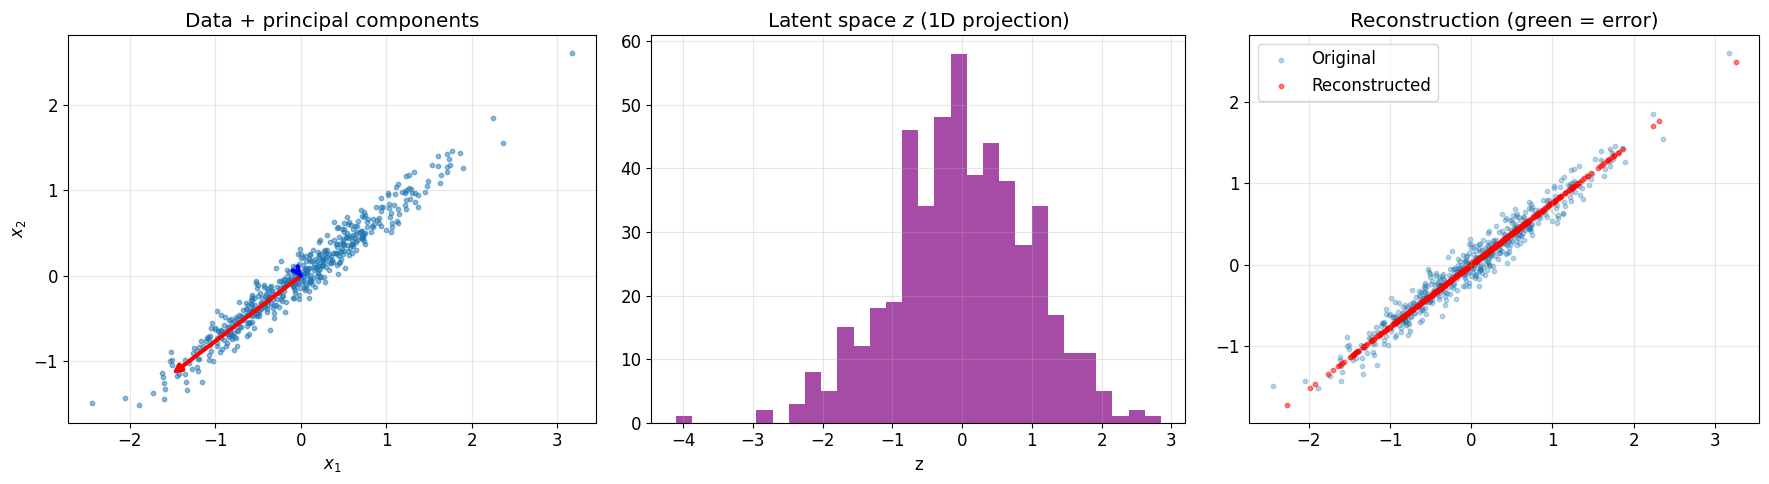

In [2]:
# Generate 2D data that lies mostly along one direction
np.random.seed(42)
n_points = 500
# Data lies along a tilted line with some spread
t = np.random.randn(n_points)
noise = np.random.randn(n_points) * 0.2
data_2d = np.stack([t * 0.8 + noise * 0.3, t * 0.6 + noise * 0.9], axis=1)
data_2d = data_2d - data_2d.mean(axis=0)  # center

# PCA: find the principal direction
cov_matrix = np.cov(data_2d.T)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
# Sort by eigenvalue (largest first)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Project to 1D (encode) and reconstruct (decode)
principal_dir = eigenvectors[:, 0]  # first principal component
z_pca = data_2d @ principal_dir  # encode: project onto 1st PC
reconstructed_pca = np.outer(z_pca, principal_dir)  # decode: reconstruct from 1D

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original data with principal directions
axes[0].scatter(data_2d[:, 0], data_2d[:, 1], s=10, alpha=0.5)
for i, (ev, ew) in enumerate(zip(eigenvectors.T, eigenvalues)):
    axes[0].annotate('', xy=ev*ew*2, xytext=(0, 0),
                     arrowprops=dict(arrowstyle='->', lw=3,
                                     color=['red', 'blue'][i]))
axes[0].set_title('Data + principal components')
axes[0].set_aspect('equal'); axes[0].grid(True, alpha=0.3)
axes[0].set_xlabel('$x_1$'); axes[0].set_ylabel('$x_2$')

# Latent space (1D)
axes[1].hist(z_pca, bins=30, alpha=0.7, color='purple')
axes[1].set_title('Latent space $z$ (1D projection)')
axes[1].set_xlabel('z'); axes[1].grid(True, alpha=0.3)

# Reconstruction
axes[2].scatter(data_2d[:, 0], data_2d[:, 1], s=10, alpha=0.3, label='Original')
axes[2].scatter(reconstructed_pca[:, 0], reconstructed_pca[:, 1], s=10, alpha=0.5,
                color='red', label='Reconstructed')
for i in range(0, n_points, 20):
    axes[2].plot([data_2d[i, 0], reconstructed_pca[i, 0]],
                [data_2d[i, 1], reconstructed_pca[i, 1]], 'g-', alpha=0.2)
axes[2].set_title('Reconstruction (green = error)')
axes[2].set_aspect('equal'); axes[2].grid(True, alpha=0.3)
axes[2].legend()

print(f"Variance explained by 1st PC: {eigenvalues[0]/eigenvalues.sum():.1%}")
print(f"Compression: 2D -> 1D (50% size)")
print(f"Reconstruction MSE: {np.mean((data_2d - reconstructed_pca)**2):.4f}")

plt.tight_layout()
plt.show()

## 1.3 Nonlinear autoencoder

Linear projection can't capture curved structures. A **neural network autoencoder** can learn nonlinear compression. Let's compress data that lies on a curve (which PCA would struggle with).

In [3]:
# Generate data on a half-circle (nonlinear 1D manifold in 2D)
np.random.seed(42)
t = np.random.uniform(0, np.pi, 1000)
x1 = np.cos(t) + np.random.randn(1000) * 0.05
x2 = np.sin(t) + np.random.randn(1000) * 0.05
data_curve = np.stack([x1, x2], axis=1).astype(np.float32)

# Neural network autoencoder: 2D -> 1D -> 2D
class Autoencoder(nn.Module):
    def __init__(self, input_dim=2, latent_dim=1, hidden_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )
    
    def encode(self, x):
        return self.encoder(x)
    
    def decode(self, z):
        return self.decoder(z)
    
    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z

# Train
data_tensor = torch.tensor(data_curve).to(device)
dataset = TensorDataset(data_tensor)
loader = DataLoader(dataset, batch_size=128, shuffle=True)

ae = Autoencoder().to(device)
optimizer = optim.Adam(ae.parameters(), lr=1e-3)

losses = []
for epoch in range(300):
    for (batch,) in loader:
        recon, z = ae(batch)
        loss = ((recon - batch)**2).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

print(f"Final reconstruction MSE: {losses[-1]:.6f}")

Final reconstruction MSE: 0.001282


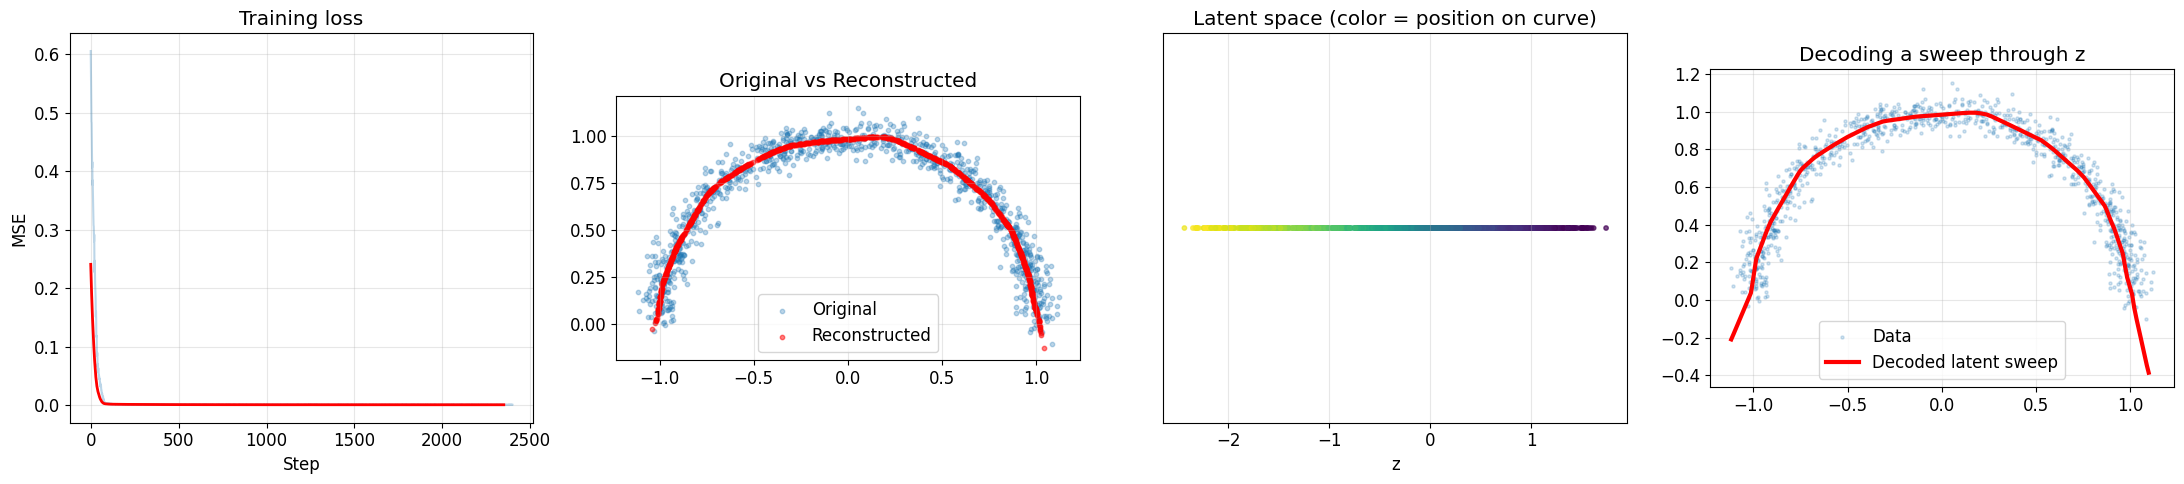

In [4]:
# Visualize the autoencoder
ae.eval()
with torch.no_grad():
    recon_all, z_all = ae(data_tensor)
    recon_np = recon_all.cpu().numpy()
    z_np = z_all.cpu().numpy().flatten()

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# Training loss
axes[0].plot(losses, alpha=0.3)
axes[0].plot(np.convolve(losses, np.ones(50)/50, mode='valid'), 'r-', linewidth=2)
axes[0].set_xlabel('Step'); axes[0].set_ylabel('MSE')
axes[0].set_title('Training loss'); axes[0].grid(True, alpha=0.3)

# Original vs reconstructed
axes[1].scatter(data_curve[:, 0], data_curve[:, 1], s=10, alpha=0.3, label='Original')
axes[1].scatter(recon_np[:, 0], recon_np[:, 1], s=10, alpha=0.5, c='red', label='Reconstructed')
axes[1].set_title('Original vs Reconstructed')
axes[1].set_aspect('equal'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Latent space (colored by position on curve)
axes[2].scatter(z_np, np.zeros_like(z_np), c=t, cmap='viridis', s=10, alpha=0.7)
axes[2].set_title('Latent space (color = position on curve)')
axes[2].set_xlabel('z'); axes[2].grid(True, alpha=0.3)
axes[2].set_yticks([])

# Decode a sweep through latent space
z_sweep = torch.linspace(z_np.min() - 0.5, z_np.max() + 0.5, 200).unsqueeze(1).to(device)
with torch.no_grad():
    decoded_sweep = ae.decode(z_sweep).cpu().numpy()
axes[3].scatter(data_curve[:, 0], data_curve[:, 1], s=5, alpha=0.2, label='Data')
axes[3].plot(decoded_sweep[:, 0], decoded_sweep[:, 1], 'r-', linewidth=3,
             label='Decoded latent sweep')
axes[3].set_title('Decoding a sweep through z')
axes[3].set_aspect('equal'); axes[3].legend(); axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The neural autoencoder successfully learned to unwrap the curve into a 1D latent representation and reconstruct it. But there's a problem...

## 1.4 The problem with regular autoencoders

A vanilla autoencoder's latent space can have **holes** — regions where no training data maps to. Decoding from these holes produces garbage. This makes the autoencoder useless as a generative model.

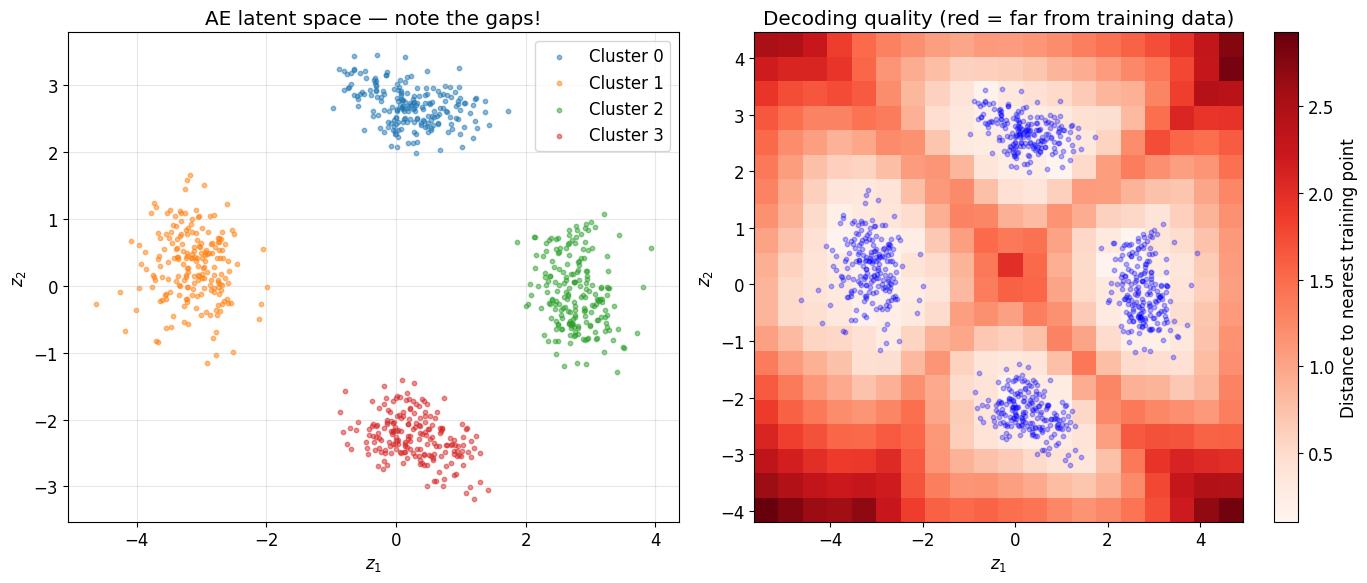

Problem: if you sample z randomly, you'll often land in a gap and get garbage!


In [5]:
# Train a 2D latent autoencoder on clustered data
np.random.seed(42)
# 4 clusters in 5D
centers = np.array([[2, 2, 0, 0, 0], [-2, 2, 0, 0, 0],
                     [2, -2, 0, 0, 0], [-2, -2, 0, 0, 0]], dtype=np.float32)
cluster_data = []
cluster_labels = []
for i, c in enumerate(centers):
    pts = c + np.random.randn(200, 5).astype(np.float32) * 0.3
    cluster_data.append(pts)
    cluster_labels.extend([i] * 200)
cluster_data = np.concatenate(cluster_data)
cluster_labels = np.array(cluster_labels)

# 5D -> 2D -> 5D autoencoder
ae2d = Autoencoder(input_dim=5, latent_dim=2, hidden_dim=64).to(device)
cluster_tensor = torch.tensor(cluster_data).to(device)
loader2 = DataLoader(TensorDataset(cluster_tensor), batch_size=128, shuffle=True)
optimizer2 = optim.Adam(ae2d.parameters(), lr=1e-3)

for epoch in range(500):
    for (batch,) in loader2:
        recon, z = ae2d(batch)
        loss = ((recon - batch)**2).mean()
        optimizer2.zero_grad()
        loss.backward()
        optimizer2.step()

ae2d.eval()
with torch.no_grad():
    _, z2d = ae2d(cluster_tensor)
    z2d_np = z2d.cpu().numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Latent space shows gaps
for i in range(4):
    mask = cluster_labels == i
    ax1.scatter(z2d_np[mask, 0], z2d_np[mask, 1], s=10, alpha=0.5, label=f'Cluster {i}')
ax1.set_title('AE latent space — note the gaps!')
ax1.legend(); ax1.grid(True, alpha=0.3)
ax1.set_xlabel('$z_1$'); ax1.set_ylabel('$z_2$')

# Decode from a grid covering the latent space
z1_range = np.linspace(z2d_np[:, 0].min() - 1, z2d_np[:, 0].max() + 1, 20)
z2_range = np.linspace(z2d_np[:, 1].min() - 1, z2d_np[:, 1].max() + 1, 20)
Z1, Z2 = np.meshgrid(z1_range, z2_range)
z_grid = torch.tensor(np.stack([Z1.ravel(), Z2.ravel()], axis=1), dtype=torch.float32).to(device)

with torch.no_grad():
    decoded_grid = ae2d.decode(z_grid).cpu().numpy()

# Compute reconstruction quality: distance to nearest training point
from scipy.spatial.distance import cdist
dists = cdist(decoded_grid, cluster_data).min(axis=1).reshape(Z1.shape)

im = ax2.imshow(dists, extent=[z1_range[0], z1_range[-1], z2_range[0], z2_range[-1]],
                origin='lower', cmap='Reds', aspect='auto')
for i in range(4):
    mask = cluster_labels == i
    ax2.scatter(z2d_np[mask, 0], z2d_np[mask, 1], s=10, alpha=0.3, c='blue')
ax2.set_title('Decoding quality (red = far from training data)')
plt.colorbar(im, ax=ax2, label='Distance to nearest training point')
ax2.set_xlabel('$z_1$'); ax2.set_ylabel('$z_2$')

plt.tight_layout()
plt.show()
print("Problem: if you sample z randomly, you'll often land in a gap and get garbage!")

The autoencoder has no reason to organize its latent space nicely — it only cares about reconstruction. The gaps between clusters mean we can't sample random latent codes and expect good outputs. This is the problem VAEs solve.

---
# Part 2: Variational Autoencoders (VAEs)

## 2.1 The key idea: make the encoder probabilistic

Instead of mapping each input to a single point $z$, a VAE maps it to a **distribution** $q(z|x) = \mathcal{N}(\mu(x), \sigma^2(x))$:

$$\text{Input } \mathbf{x} \xrightarrow{\text{Encoder}} (\boldsymbol{\mu}, \boldsymbol{\sigma}) \xrightarrow{\text{Sample}} \mathbf{z} \sim \mathcal{N}(\boldsymbol{\mu}, \text{diag}(\boldsymbol{\sigma}^2)) \xrightarrow{\text{Decoder}} \hat{\mathbf{x}}$$

Plus a **regularizer** that pushes $q(z|x)$ toward a standard normal $\mathcal{N}(0, I)$. This fills the gaps!

## 2.2 The reparameterization trick

**Problem**: We can't backpropagate through a random sampling operation $z \sim \mathcal{N}(\mu, \sigma^2)$.

**Solution**: Reparameterize as:
$$z = \mu + \sigma \cdot \epsilon, \quad \epsilon \sim \mathcal{N}(0, I)$$

Now $z$ is a deterministic function of $\mu$, $\sigma$, and $\epsilon$. Gradients flow through $\mu$ and $\sigma$ while the randomness is isolated in $\epsilon$.

This is a fundamental trick that appears throughout modern ML (also used in diffusion models when sampling $x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1-\bar{\alpha}_t} \epsilon$).

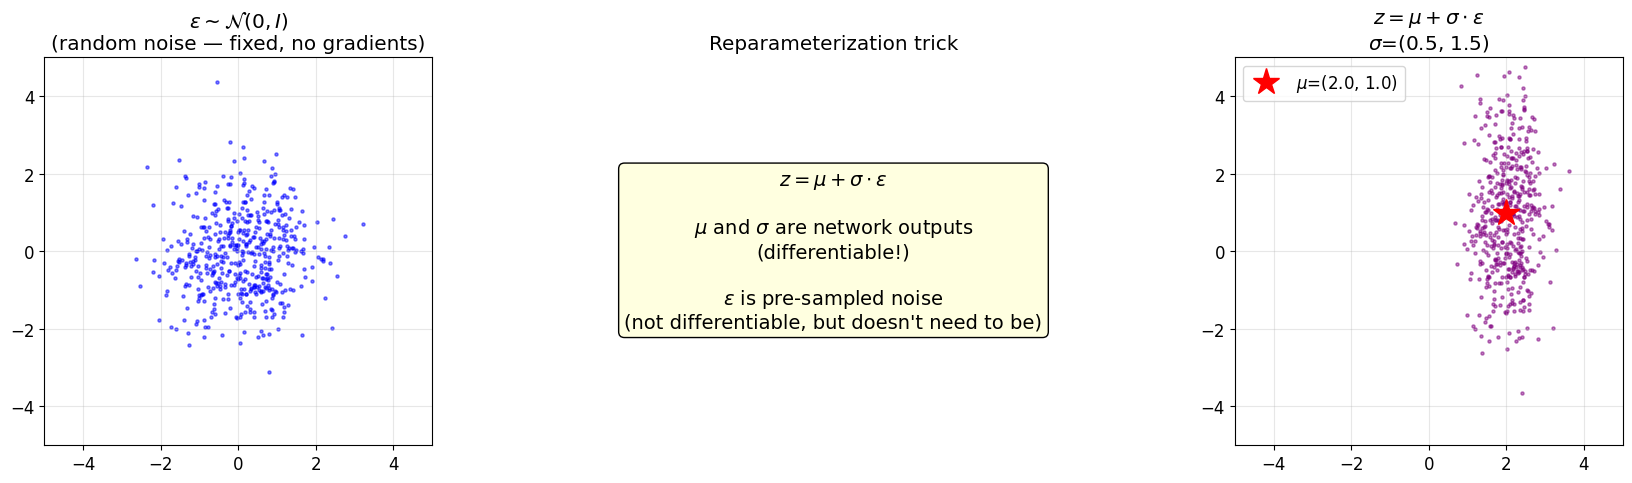

In [6]:
# Visualize the reparameterization trick
mu = torch.tensor([2.0, 1.0])
sigma = torch.tensor([0.5, 1.5])

# Sample 500 points using the trick
epsilon = torch.randn(500, 2)
z = mu + sigma * epsilon

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Standard normal samples (epsilon)
axes[0].scatter(epsilon[:, 0], epsilon[:, 1], s=5, alpha=0.5, c='blue')
axes[0].set_title('$\\epsilon \\sim \\mathcal{N}(0, I)$\n(random noise — fixed, no gradients)')
axes[0].set_xlim(-5, 5); axes[0].set_ylim(-5, 5)
axes[0].set_aspect('equal'); axes[0].grid(True, alpha=0.3)

# Arrow showing the transform
axes[1].text(0.5, 0.5, '$z = \\mu + \\sigma \\cdot \\epsilon$\n\n'
             '$\\mu$ and $\\sigma$ are network outputs\n'
             '(differentiable!)\n\n'
             '$\\epsilon$ is pre-sampled noise\n'
             '(not differentiable, but doesn\'t need to be)',
             ha='center', va='center', fontsize=14,
             bbox=dict(boxstyle='round', facecolor='lightyellow'))
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1)
axes[1].axis('off')
axes[1].set_title('Reparameterization trick')

# Reparameterized samples
axes[2].scatter(z[:, 0], z[:, 1], s=5, alpha=0.5, c='purple')
axes[2].plot(mu[0], mu[1], 'r*', markersize=20, label=f'$\\mu$=({mu[0]:.1f}, {mu[1]:.1f})')
axes[2].set_title(f'$z = \\mu + \\sigma \\cdot \\epsilon$\n'
                   f'$\\sigma$=({sigma[0]:.1f}, {sigma[1]:.1f})')
axes[2].set_xlim(-5, 5); axes[2].set_ylim(-5, 5)
axes[2].set_aspect('equal'); axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# Demonstrate that gradients flow through the reparameterization
mu = torch.tensor([1.0, 2.0], requires_grad=True)
log_var = torch.tensor([0.0, 0.0], requires_grad=True)  # log(sigma^2)
sigma = torch.exp(0.5 * log_var)  # sigma = exp(log_var / 2)

# Reparameterize
epsilon = torch.randn(100, 2)
z = mu + sigma * epsilon  # (100, 2)

# Some downstream loss (e.g., z should be close to target [3, 3])
target = torch.tensor([3.0, 3.0])
loss = ((z - target)**2).mean()
loss.backward()

print("Gradients flow through the reparameterization trick:")
print(f"  d(loss)/d(mu)      = {mu.grad.numpy()}  (nonzero - gradients flow!)")
print(f"  d(loss)/d(log_var) = {log_var.grad.numpy()}  (nonzero - gradients flow!)")
print(f"\nWithout the trick, sampling z ~ N(mu, sigma^2) would block gradients.")

Gradients flow through the reparameterization trick:
  d(loss)/d(mu)      = [-2.0729122 -1.0827427]  (nonzero - gradients flow!)
  d(loss)/d(log_var) = [0.52881444 0.6654624 ]  (nonzero - gradients flow!)

Without the trick, sampling z ~ N(mu, sigma^2) would block gradients.


## 2.3 The ELBO and VAE loss function

The VAE is derived from **variational inference** (see 0b §3.2 for the derivation and a numerical check). We want to maximize the data likelihood $\log p(\mathbf{x})$, but this is intractable. Instead, we maximize a lower bound called the **Evidence Lower Bound (ELBO)**:

$$\log p(\mathbf{x}) \geq \underbrace{\mathbb{E}_{q(z|x)}[\log p(\mathbf{x}|\mathbf{z})]}_\text{Reconstruction} - \underbrace{D_{KL}(q(\mathbf{z}|\mathbf{x}) \| p(\mathbf{z}))}_\text{KL Regularization}$$

The gap in this inequality is $D_{KL}(q(z\mid x)\,\|\,p(z\mid x))$, i.e. how far the encoder is from the true posterior.

**Where the MSE comes from.** If the decoder defines a Gaussian likelihood $p(x \mid z) = \mathcal{N}(x;\ \text{dec}(z),\ \sigma_{\text{dec}}^2 I)$, then $-\log p(x\mid z) = \frac{1}{2\sigma_{\text{dec}}^2}\|x - \text{dec}(z)\|^2 + \text{const}$. The negative ELBO is therefore

$$\mathcal{L}_{\text{VAE}} = \underbrace{\|\mathbf{x} - \hat{\mathbf{x}}\|^2}_{\text{Reconstruction loss}} + \underbrace{\beta \cdot D_{KL}(q(\mathbf{z}|\mathbf{x}) \| \mathcal{N}(0, I))}_{\text{KL regularization}}, \qquad \beta = 2\sigma_{\text{dec}}^2$$

So $\beta$ is not an arbitrary knob: it encodes how noisy you assume the data is around the decoder output. $\beta = 1$ with a summed squared error corresponds to $\sigma^2_{\text{dec}} = 0.5$. If the reconstruction term is a *mean* over pixels instead of a sum (as in many implementations), the effective $\beta$ changes by a factor of the number of pixels.

### The KL term (closed form for Gaussians)

For $q(z|x) = \mathcal{N}(\mu, \text{diag}(\sigma^2))$ and $p(z) = \mathcal{N}(0, I)$, each latent dimension contributes $\tfrac12(\mu_j^2 + \sigma_j^2 - 1 - \log\sigma_j^2)$, so in total:

$$D_{KL} = -\frac{1}{2} \sum_{j=1}^{d} \left(1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

Let's verify this numerically and build intuition.

In [8]:
# KL divergence between N(mu, sigma^2) and N(0, 1)
def kl_divergence(mu, log_var):
    """KL(N(mu, sigma^2) || N(0, 1)), closed form.
    log_var = log(sigma^2)
    """
    return -0.5 * torch.sum(1 + log_var - mu**2 - log_var.exp())

# Verify: KL should be 0 when mu=0, sigma=1
print("KL divergence from N(0,1):")
print(f"  N(0, 1):   {kl_divergence(torch.tensor([0.0]), torch.tensor([0.0])).item():.4f}  (should be 0)")
print(f"  N(1, 1):   {kl_divergence(torch.tensor([1.0]), torch.tensor([0.0])).item():.4f}  (shifted mean)")
print(f"  N(0, 2):   {kl_divergence(torch.tensor([0.0]), torch.tensor([np.log(4.0)])).item():.4f}  (wider)")
print(f"  N(0, 0.5): {kl_divergence(torch.tensor([0.0]), torch.tensor([np.log(0.25)])).item():.4f}  (narrower)")
print(f"  N(2, 0.5): {kl_divergence(torch.tensor([2.0]), torch.tensor([np.log(0.25)])).item():.4f}  (shifted + narrower)")

KL divergence from N(0,1):
  N(0, 1):   -0.0000  (should be 0)
  N(1, 1):   0.5000  (shifted mean)
  N(0, 2):   0.8069  (wider)
  N(0, 0.5): 0.3181  (narrower)
  N(2, 0.5): 2.3181  (shifted + narrower)


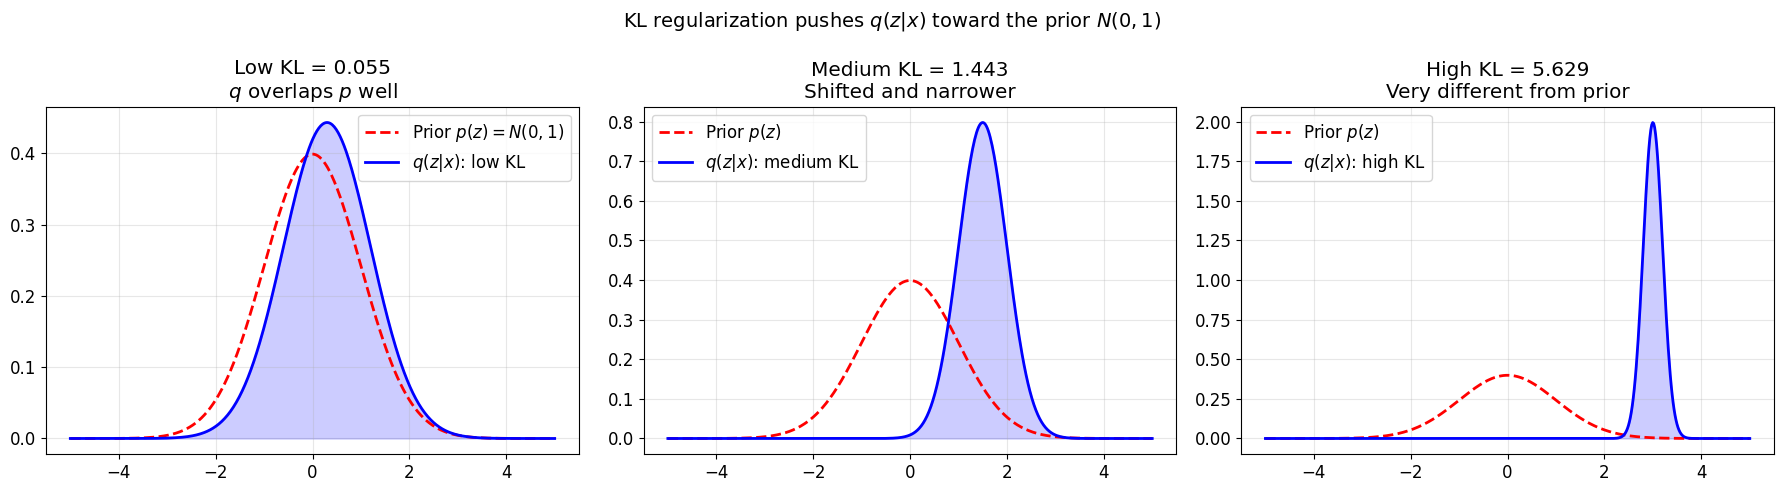

In [9]:
# Visualize what KL regularization does
x = np.linspace(-5, 5, 500)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Show q(z|x) for different KL penalties
from scipy.stats import norm as scipy_norm

# Low KL: q is close to N(0,1)
axes[0].plot(x, scipy_norm.pdf(x, 0, 1), 'r--', linewidth=2, label='Prior $p(z) = N(0,1)$')
axes[0].plot(x, scipy_norm.pdf(x, 0.3, 0.9), 'b-', linewidth=2, label='$q(z|x)$: low KL')
axes[0].fill_between(x, scipy_norm.pdf(x, 0.3, 0.9), alpha=0.2, color='blue')
kl = kl_divergence(torch.tensor([0.3]), torch.tensor([2*np.log(0.9)])).item()
axes[0].set_title(f'Low KL = {kl:.3f}\n$q$ overlaps $p$ well')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Medium KL
axes[1].plot(x, scipy_norm.pdf(x, 0, 1), 'r--', linewidth=2, label='Prior $p(z)$')
axes[1].plot(x, scipy_norm.pdf(x, 1.5, 0.5), 'b-', linewidth=2, label='$q(z|x)$: medium KL')
axes[1].fill_between(x, scipy_norm.pdf(x, 1.5, 0.5), alpha=0.2, color='blue')
kl = kl_divergence(torch.tensor([1.5]), torch.tensor([2*np.log(0.5)])).item()
axes[1].set_title(f'Medium KL = {kl:.3f}\nShifted and narrower')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

# High KL
axes[2].plot(x, scipy_norm.pdf(x, 0, 1), 'r--', linewidth=2, label='Prior $p(z)$')
axes[2].plot(x, scipy_norm.pdf(x, 3, 0.2), 'b-', linewidth=2, label='$q(z|x)$: high KL')
axes[2].fill_between(x, scipy_norm.pdf(x, 3, 0.2), alpha=0.2, color='blue')
kl = kl_divergence(torch.tensor([3.0]), torch.tensor([2*np.log(0.2)])).item()
axes[2].set_title(f'High KL = {kl:.3f}\nVery different from prior')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle('KL regularization pushes $q(z|x)$ toward the prior $N(0,1)$', fontsize=14)
plt.tight_layout()
plt.show()

## 2.4 Building and training a VAE

Let's train a full VAE on the 4-cluster data and compare its latent space to the regular autoencoder.

In [10]:
class VAE(nn.Module):
    def __init__(self, input_dim=5, latent_dim=2, hidden_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        
        # Encoder outputs mu and log_var (2 * latent_dim outputs)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_log_var = nn.Linear(hidden_dim, latent_dim)
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )
    
    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        log_var = self.fc_log_var(h)
        return mu, log_var
    
    def reparameterize(self, mu, log_var):
        """The reparameterization trick: z = mu + sigma * epsilon"""
        sigma = torch.exp(0.5 * log_var)  # sigma = sqrt(exp(log_var))
        epsilon = torch.randn_like(sigma)  # sample epsilon ~ N(0, I)
        return mu + sigma * epsilon
    
    def decode(self, z):
        return self.decoder(z)
    
    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        recon = self.decode(z)
        return recon, mu, log_var, z

def vae_loss(recon, x, mu, log_var, beta=1.0):
    """VAE loss = reconstruction + beta * KL divergence"""
    recon_loss = ((recon - x)**2).sum(dim=1).mean()
    kl_loss = -0.5 * torch.sum(1 + log_var - mu**2 - log_var.exp(), dim=1).mean()
    return recon_loss + beta * kl_loss, recon_loss, kl_loss

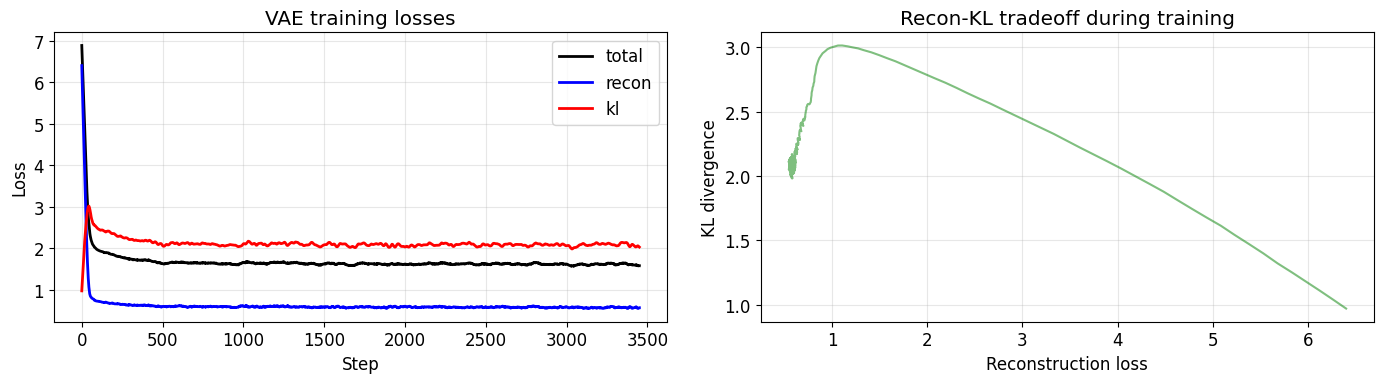

In [11]:
# Train the VAE on the same 4-cluster data
vae = VAE(input_dim=5, latent_dim=2, hidden_dim=64).to(device)
optimizer_vae = optim.Adam(vae.parameters(), lr=1e-3)
loader_vae = DataLoader(TensorDataset(cluster_tensor), batch_size=128, shuffle=True)

history = {'total': [], 'recon': [], 'kl': []}
beta = 0.5  # weight for KL term

for epoch in range(500):
    for (batch,) in loader_vae:
        recon, mu, log_var, z = vae(batch)
        loss, recon_l, kl_l = vae_loss(recon, batch, mu, log_var, beta=beta)
        optimizer_vae.zero_grad()
        loss.backward()
        optimizer_vae.step()
        history['total'].append(loss.item())
        history['recon'].append(recon_l.item())
        history['kl'].append(kl_l.item())

# Plot training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
window = 50
for key, color in [('total', 'black'), ('recon', 'blue'), ('kl', 'red')]:
    smoothed = np.convolve(history[key], np.ones(window)/window, mode='valid')
    ax1.plot(smoothed, color=color, label=key, linewidth=2)
ax1.set_xlabel('Step'); ax1.set_ylabel('Loss')
ax1.set_title('VAE training losses'); ax1.legend(); ax1.grid(True, alpha=0.3)

# Reconstruction vs KL tradeoff
ax2.plot(np.convolve(history['recon'], np.ones(window)/window, mode='valid'),
         np.convolve(history['kl'], np.ones(window)/window, mode='valid'),
         'g-', alpha=0.5)
ax2.set_xlabel('Reconstruction loss'); ax2.set_ylabel('KL divergence')
ax2.set_title('Recon-KL tradeoff during training')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

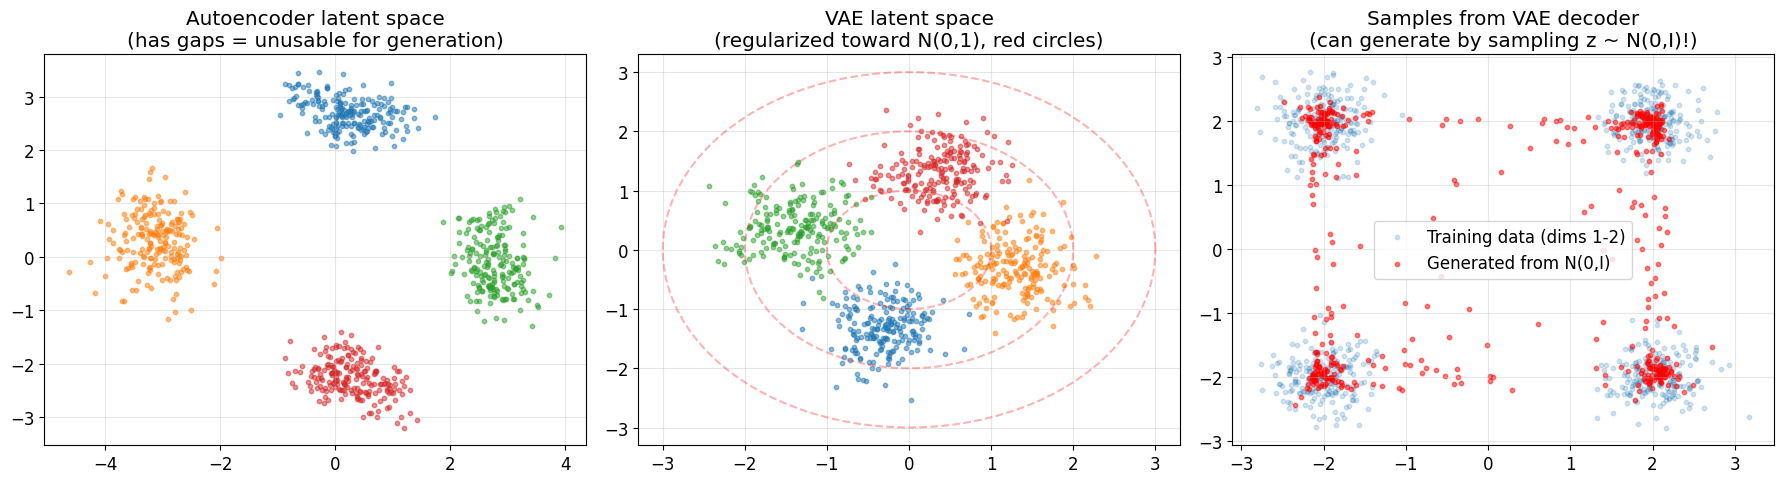

In [12]:
# Compare AE vs VAE latent spaces
vae.eval()
with torch.no_grad():
    _, mu_all, log_var_all, z_vae = vae(cluster_tensor)
    z_vae_np = z_vae.cpu().numpy()
    mu_np = mu_all.cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# AE latent space (from earlier)
for i in range(4):
    mask = cluster_labels == i
    axes[0].scatter(z2d_np[mask, 0], z2d_np[mask, 1], s=10, alpha=0.5)
axes[0].set_title('Autoencoder latent space\n(has gaps = unusable for generation)')
axes[0].grid(True, alpha=0.3)

# VAE latent space
for i in range(4):
    mask = cluster_labels == i
    axes[1].scatter(z_vae_np[mask, 0], z_vae_np[mask, 1], s=10, alpha=0.5)
# Draw the N(0,1) contours
theta = np.linspace(0, 2*np.pi, 100)
for r in [1, 2, 3]:
    axes[1].plot(r*np.cos(theta), r*np.sin(theta), 'r--', alpha=0.3)
axes[1].set_title('VAE latent space\n(regularized toward N(0,1), red circles)')
axes[1].grid(True, alpha=0.3)

# VAE: sample from N(0,1) and decode
z_random = torch.randn(500, 2).to(device)
with torch.no_grad():
    generated = vae.decode(z_random).cpu().numpy()

axes[2].scatter(cluster_data[:, 0], cluster_data[:, 1], s=10, alpha=0.2, label='Training data (dims 1-2)')
axes[2].scatter(generated[:, 0], generated[:, 1], s=10, alpha=0.5, c='red', label='Generated from N(0,I)')
axes[2].set_title('Samples from VAE decoder\n(can generate by sampling z ~ N(0,I)!)')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**The KL term fills the gaps**: By penalizing the KL divergence from $\mathcal{N}(0, I)$, the VAE is forced to spread its latent codes across the space, ensuring that random samples from $\mathcal{N}(0, I)$ decode to plausible outputs.

## 2.5 Latent space interpolation

A well-organized latent space allows smooth interpolation between data points — another benefit of VAE regularization.

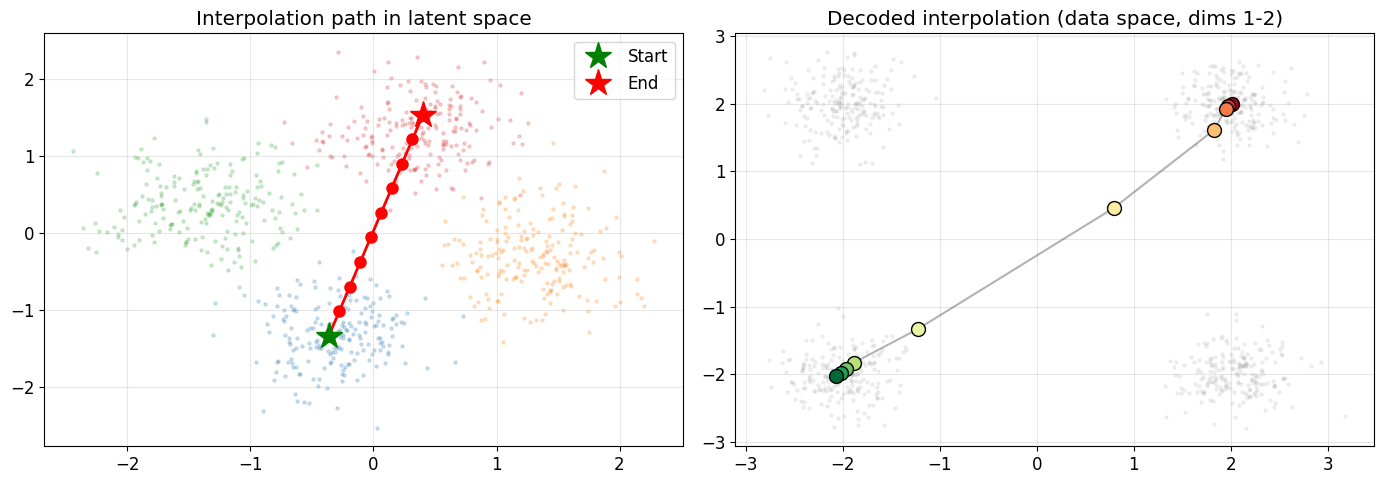

In [13]:
# Interpolate between two data points in latent space
vae.eval()

# Pick two points from different clusters
x_a = cluster_tensor[0:1]   # cluster 0
x_b = cluster_tensor[600:601]  # cluster 3

with torch.no_grad():
    mu_a, _ = vae.encode(x_a)
    mu_b, _ = vae.encode(x_b)

# Linear interpolation in latent space
n_interp = 10
alphas = torch.linspace(0, 1, n_interp).unsqueeze(1).to(device)
z_interp = (1 - alphas) * mu_a + alphas * mu_b

with torch.no_grad():
    x_interp = vae.decode(z_interp).cpu().numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Latent space path
for i in range(4):
    mask = cluster_labels == i
    ax1.scatter(z_vae_np[mask, 0], z_vae_np[mask, 1], s=5, alpha=0.2)

z_interp_np = z_interp.cpu().numpy()
ax1.plot(z_interp_np[:, 0], z_interp_np[:, 1], 'r-o', linewidth=2, markersize=8)
ax1.plot(z_interp_np[0, 0], z_interp_np[0, 1], 'g*', markersize=20, label='Start')
ax1.plot(z_interp_np[-1, 0], z_interp_np[-1, 1], 'r*', markersize=20, label='End')
ax1.set_title('Interpolation path in latent space')
ax1.legend(); ax1.grid(True, alpha=0.3)

# Decoded interpolation (first 2 dims)
ax2.scatter(cluster_data[:, 0], cluster_data[:, 1], s=5, alpha=0.1, c='gray')
colors = plt.cm.RdYlGn(np.linspace(0, 1, n_interp))
for i in range(n_interp):
    ax2.scatter(x_interp[i, 0], x_interp[i, 1], c=[colors[i]], s=100, 
                edgecolors='black', zorder=5)
    if i < n_interp - 1:
        ax2.plot([x_interp[i, 0], x_interp[i+1, 0]],
                [x_interp[i, 1], x_interp[i+1, 1]], 'k-', alpha=0.3)
ax2.set_title('Decoded interpolation (data space, dims 1-2)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2.6 The beta-VAE tradeoff

The $\beta$ parameter controls the balance between reconstruction quality and latent space regularity:

$$\mathcal{L} = \mathcal{L}_{\text{recon}} + \beta \cdot \mathcal{L}_{KL}$$

- $\beta \to 0$: Behaves like a regular autoencoder (good reconstruction, messy latent space)
- $\beta \to \infty$: Perfect latent space ($z \sim N(0,I)$) but terrible reconstruction
- Sweet spot: Good enough reconstruction with a smooth, usable latent space

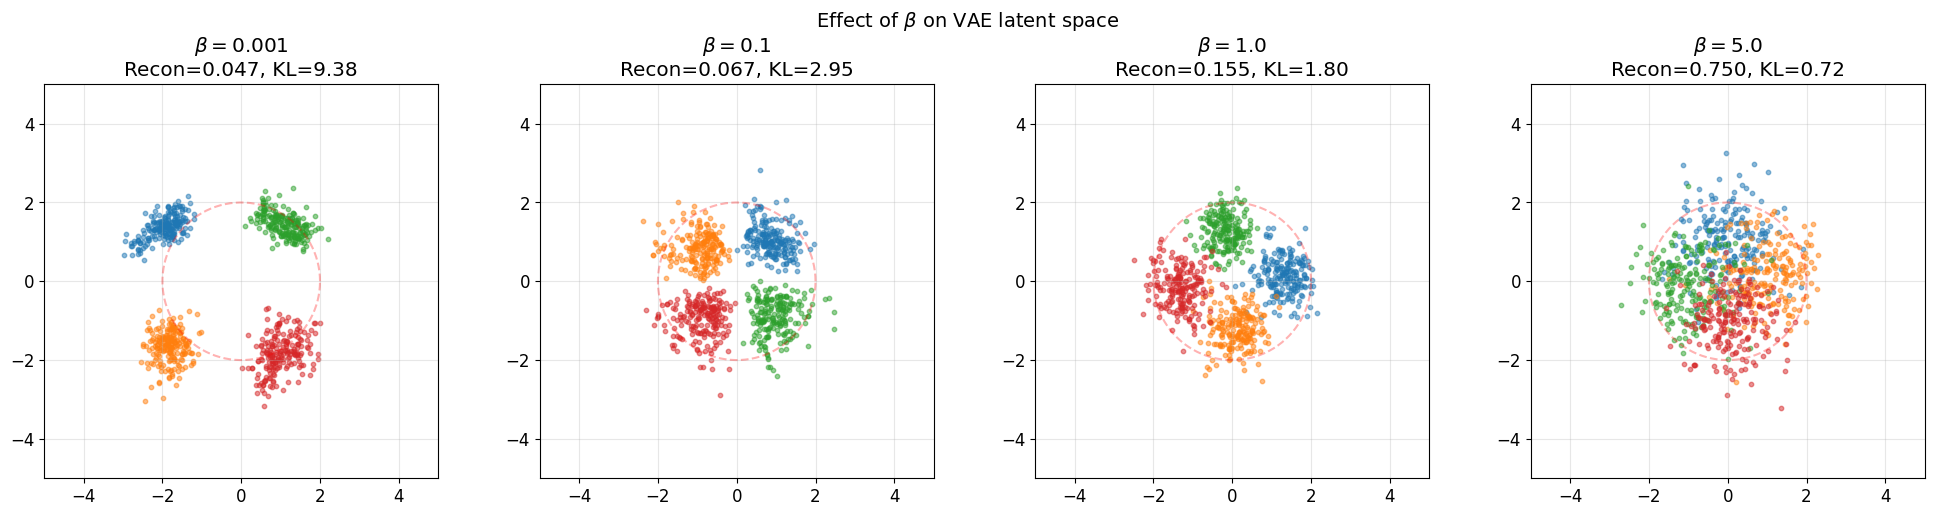

In [14]:
# Train VAEs with different beta values
betas_to_try = [0.001, 0.1, 1.0, 5.0]
results = {}

for beta_val in betas_to_try:
    model_b = VAE(input_dim=5, latent_dim=2, hidden_dim=64).to(device)
    opt_b = optim.Adam(model_b.parameters(), lr=1e-3)
    
    for epoch in range(500):
        for (batch,) in loader_vae:
            recon, mu, lv, z = model_b(batch)
            loss, _, _ = vae_loss(recon, batch, mu, lv, beta=beta_val)
            opt_b.zero_grad()
            loss.backward()
            opt_b.step()
    
    model_b.eval()
    with torch.no_grad():
        recon_all, mu_all, lv_all, z_all = model_b(cluster_tensor)
        recon_mse = ((recon_all - cluster_tensor)**2).mean().item()
        kl_val = -0.5 * torch.sum(1 + lv_all - mu_all**2 - lv_all.exp(), dim=1).mean().item()
    
    results[beta_val] = {
        'z': z_all.cpu().numpy(),
        'recon_mse': recon_mse,
        'kl': kl_val,
        'model': model_b
    }

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, beta_val in zip(axes, betas_to_try):
    z = results[beta_val]['z']
    for i in range(4):
        mask = cluster_labels == i
        ax.scatter(z[mask, 0], z[mask, 1], s=10, alpha=0.5)
    # N(0,1) circle
    theta = np.linspace(0, 2*np.pi, 100)
    ax.plot(2*np.cos(theta), 2*np.sin(theta), 'r--', alpha=0.3)
    ax.set_title(f'$\\beta={beta_val}$\nRecon={results[beta_val]["recon_mse"]:.3f}, '
                 f'KL={results[beta_val]["kl"]:.2f}')
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)

plt.suptitle('Effect of $\\beta$ on VAE latent space', fontsize=14)
plt.tight_layout()
plt.show()

**Summary of Part 2**: The VAE gives us:
1. An **encoder** that compresses data to a smooth latent space
2. A **decoder** that can generate data from latent codes
3. A latent space where $z \sim \mathcal{N}(0, I)$ produces valid outputs

In notebook 5 (Latent Diffusion), the VAE compresses 32x32x1 images (1024 numbers) to 4x4x4 latent tensors (64 numbers), a **16x** reduction in dimension, and then diffusion runs in this small space. (The *spatial* resolution shrinks 64x, 32x32 → 4x4, but the latent has 4 channels.)

---
# Part 3: Energy Functions and Boltzmann Distributions

## 3.1 Energy functions: scoring quality

An **energy function** $E(\mathbf{x})$ assigns a scalar value to any input. Lower energy means the input is more "natural" or "high quality":

- Low energy: likely data (good samples)
- High energy: unlikely data (noise, artifacts)

This is used directly in notebooks 6 (steering generation) and 7 (energy-based modeling).

## 3.2 The Boltzmann distribution

Energy and probability are connected through the **Boltzmann distribution** (from statistical physics):

$$p(\mathbf{x}) = \frac{1}{Z} \exp(-E(\mathbf{x}))$$

where $Z = \int \exp(-E(\mathbf{x})) d\mathbf{x}$ is the **partition function** (normalizing constant).

Key properties:
- Low energy $\Leftrightarrow$ high probability
- The partition function $Z$ is typically **intractable**: you can't compute the integral
- But the **score function** doesn't need $Z$: $\nabla_x \log p(x) = -\nabla_x E(x) - \nabla_x \log Z = -\nabla_x E(x)$
- $Z$ must be **finite** for $p$ to exist. Being bounded below ($E \geq 0$) is *not* enough: $E(x) = 0$ everywhere gives $Z = \infty$. The energy must grow fast enough as $|x| \to \infty$, e.g. at least like $|x|$.
- The energy is only defined **up to an additive constant**: $E$ and $E + c$ give the same $p$. Only energy *differences* mean anything.

This last point is crucial: **score = negative energy gradient**, and we don't need to know $Z$!

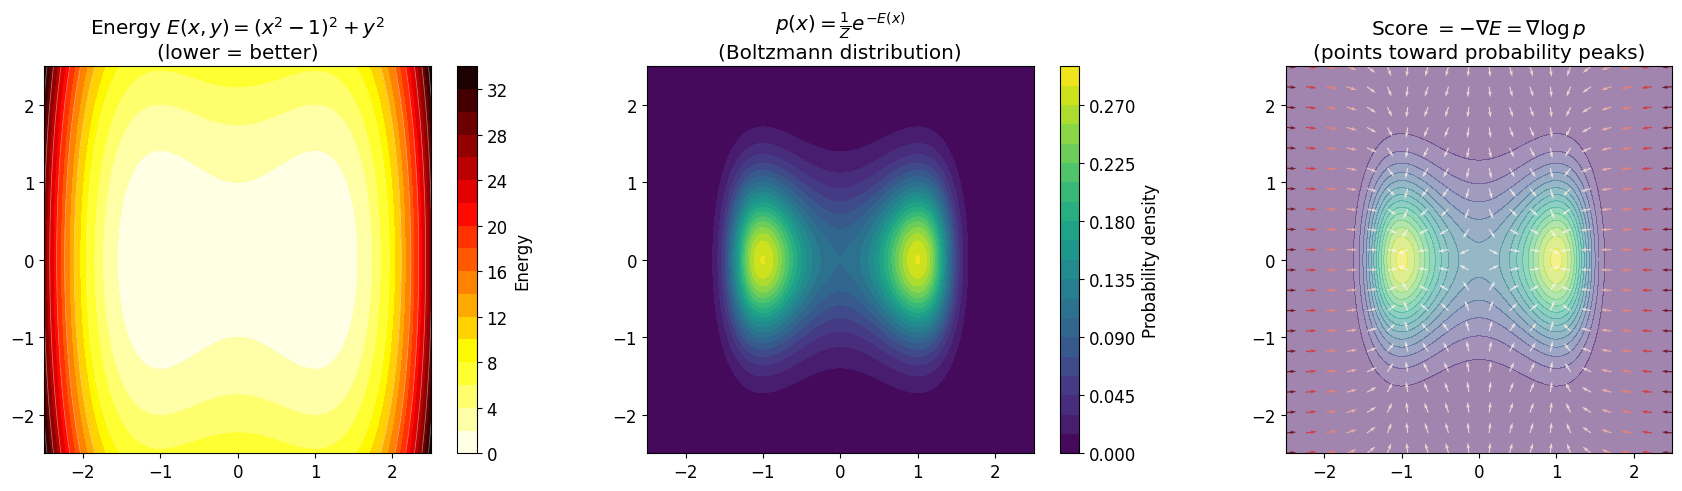

Partition function Z = 3.4970 (computed numerically by integrating exp(-E))
In practice, Z is intractable for high-dimensional data.
But the score -nabla E doesn't need Z at all!


In [15]:
# Define a 2D energy function and derive everything from it
def energy_fn(x, y):
    """A double-well energy landscape."""
    return (x**2 - 1)**2 + y**2

x = np.linspace(-2.5, 2.5, 200)
y = np.linspace(-2.5, 2.5, 200)
X, Y = np.meshgrid(x, y)
E = energy_fn(X, Y)

# Boltzmann distribution (unnormalized)
P_unnorm = np.exp(-E)
# Numerical normalization
dx = x[1] - x[0]; dy = y[1] - y[0]
Z = P_unnorm.sum() * dx * dy
P = P_unnorm / Z

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Energy landscape
cs = axes[0].contourf(X, Y, E, levels=20, cmap='hot_r')
axes[0].contour(X, Y, E, levels=10, colors='white', linewidths=0.5, alpha=0.5)
axes[0].set_title('Energy $E(x, y) = (x^2-1)^2 + y^2$\n(lower = better)')
plt.colorbar(cs, ax=axes[0], label='Energy')
axes[0].set_aspect('equal')

# Boltzmann probability
cs2 = axes[1].contourf(X, Y, P, levels=20, cmap='viridis')
axes[1].set_title('$p(x) = \\frac{1}{Z} e^{-E(x)}$\n(Boltzmann distribution)')
plt.colorbar(cs2, ax=axes[1], label='Probability density')
axes[1].set_aspect('equal')

# Score field = -grad(E)
x_q = np.linspace(-2.5, 2.5, 20)
y_q = np.linspace(-2.5, 2.5, 20)
Xq, Yq = np.meshgrid(x_q, y_q)
# Gradient of E = (dE/dx, dE/dy) = (4x(x^2-1), 2y)
dE_dx = 4 * Xq * (Xq**2 - 1)
dE_dy = 2 * Yq
# Score = -grad(E)
Sx = -dE_dx
Sy = -dE_dy

axes[2].contourf(X, Y, P, levels=15, cmap='viridis', alpha=0.5)
mag = np.sqrt(Sx**2 + Sy**2)
axes[2].quiver(Xq, Yq, Sx/(mag+1e-8), Sy/(mag+1e-8), mag, cmap='Reds', alpha=0.8)
axes[2].set_title('Score $= -\\nabla E = \\nabla \\log p$\n(points toward probability peaks)')
axes[2].set_aspect('equal')

plt.tight_layout()
plt.show()

print(f"Partition function Z = {Z:.4f} (computed numerically by integrating exp(-E))")
print(f"In practice, Z is intractable for high-dimensional data.")
print(f"But the score -nabla E doesn't need Z at all!")

## 3.3 Sampling from energy functions via Langevin dynamics

Since score = $-\nabla E$, we can use Langevin dynamics (from notebook 0b) to sample from any energy function:

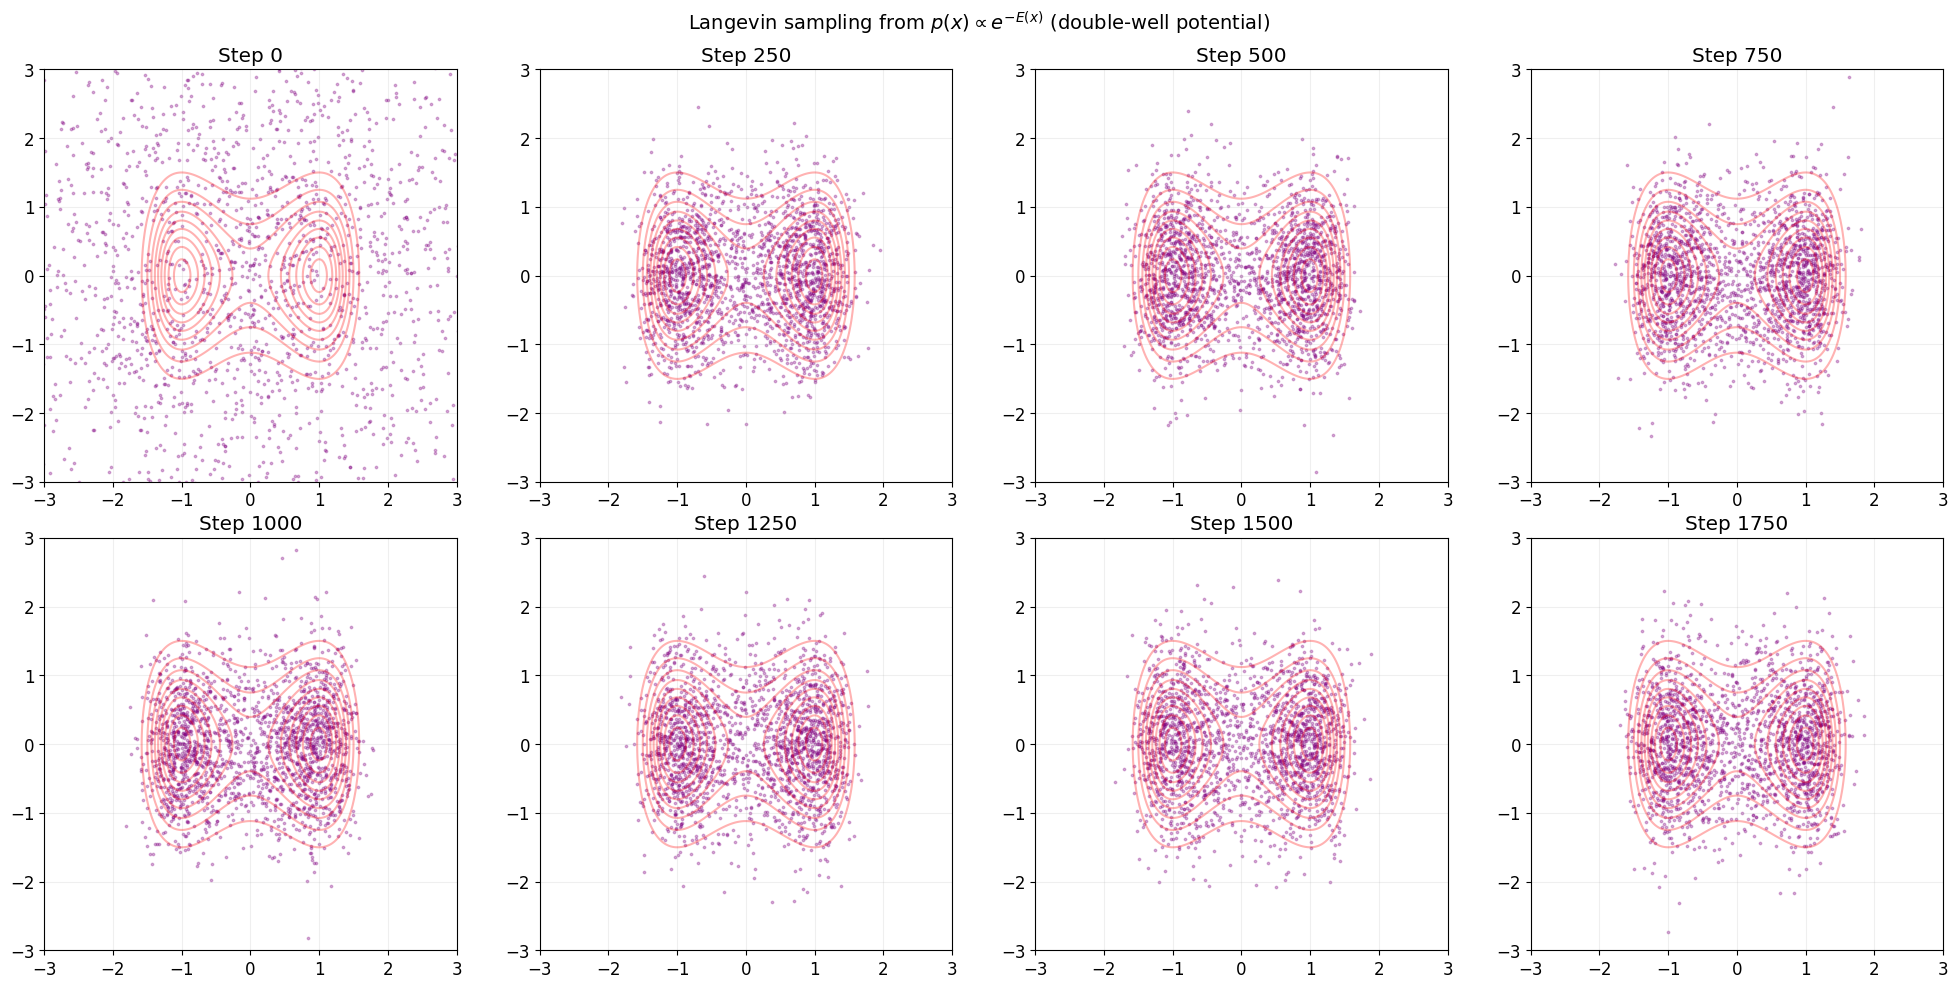

In [16]:
# Langevin dynamics on the double-well energy
def energy_score_torch(x):
    """Score = -grad(E) for the double-well energy."""
    x = x.clone().requires_grad_(True)
    E = ((x[:, 0]**2 - 1)**2 + x[:, 1]**2).sum()
    E.backward()
    return -x.grad.detach()  # score = -grad(E)

# Run Langevin dynamics
torch.manual_seed(42)
n_samples = 2000
x = torch.randn(n_samples, 2) * 2  # start from noise
epsilon = 0.01

snapshots = [x.clone()]
for step in range(2000):
    score = energy_score_torch(x)
    noise = torch.randn_like(x)
    x = x + (epsilon / 2) * score + np.sqrt(epsilon) * noise
    if (step + 1) % 250 == 0:
        snapshots.append(x.clone())

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for idx, ax in enumerate(axes.flat):
    if idx < len(snapshots):
        pts = snapshots[idx].numpy()
        ax.contour(X, Y, P, levels=10, colors='red', alpha=0.3)
        ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.3, c='purple')
        ax.set_title(f'Step {idx * 250}')
        ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
        ax.set_aspect('equal')
        ax.grid(True, alpha=0.2)

plt.suptitle('Langevin sampling from $p(x) \\propto e^{-E(x)}$ (double-well potential)', fontsize=14)
plt.tight_layout()
plt.show()

## 3.4 Energy for discrimination vs generation

An important insight from notebook 7: a learned energy function has **two uses**:

1. **Generation**: Use the score ($-\nabla E$) to run Langevin dynamics or reverse diffusion and create samples
2. **Discrimination**: Evaluate $E(x)$ to score/rank any input

Scoring is a single forward pass, while generation chains many steps and can accumulate errors, so a trained energy is often useful as a *filter* on generated samples. Two caveats: the energy is only meaningful up to a constant (compare samples at the **same** noise level $t$, never across different $t$), and it is only as good as the training data coverage. Far from the data, a learned energy can be arbitrarily wrong.

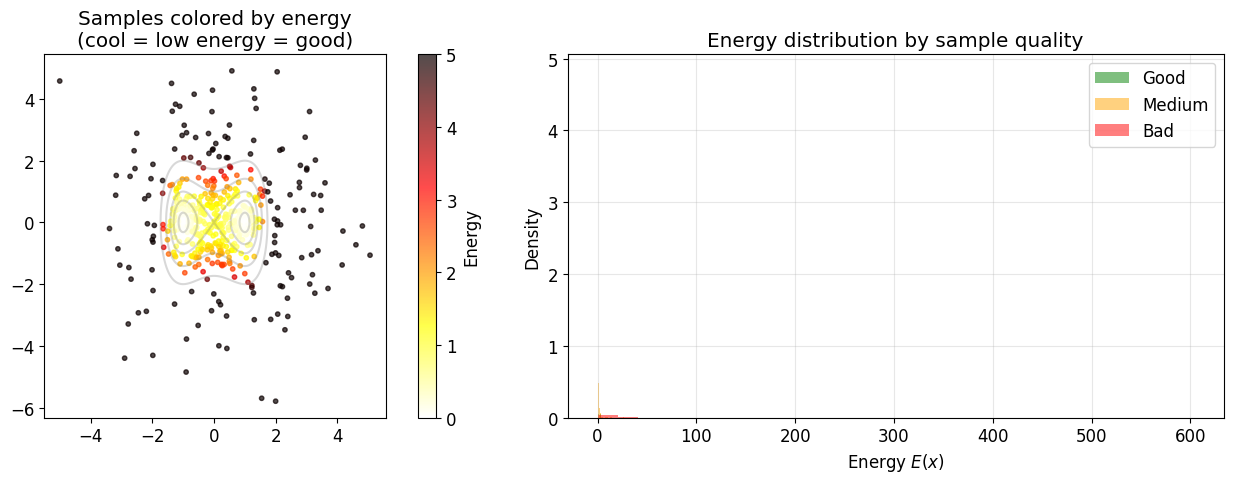

Mean energies — Good: 0.179, Medium: 1.735, Bad: 32.559
Energy reliably separates good from bad samples!


In [17]:
# Demonstrate: energy can rank sample quality
def energy_value(x):
    """Compute E(x) for the double-well."""
    return (x[:, 0]**2 - 1)**2 + x[:, 1]**2

# Generate some samples with different quality levels
np.random.seed(42)

# "Good" samples: near the energy minima at (+-1, 0)
good_samples = np.concatenate([
    np.random.randn(100, 2) * 0.2 + [1, 0],
    np.random.randn(100, 2) * 0.2 + [-1, 0]
])

# "Medium" samples: somewhat off
medium_samples = np.random.randn(200, 2) * 0.8

# "Bad" samples: far from minima
bad_samples = np.random.randn(200, 2) * 2

# Score them all
all_samples = np.concatenate([good_samples, medium_samples, bad_samples]).astype(np.float32)
labels = ['Good'] * 200 + ['Medium'] * 200 + ['Bad'] * 200
energies = energy_value(torch.tensor(all_samples)).numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scatter colored by energy
sc = ax1.scatter(all_samples[:, 0], all_samples[:, 1], c=energies, cmap='hot_r',
                  s=10, alpha=0.7, vmin=0, vmax=5)
ax1.contour(X, Y, E, levels=[0.1, 0.5, 1, 2, 4], colors='gray', alpha=0.3)
plt.colorbar(sc, ax=ax1, label='Energy')
ax1.set_title('Samples colored by energy\n(cool = low energy = good)')
ax1.set_aspect('equal')

# Energy distributions by category
for cat, start, end, color in [('Good', 0, 200, 'green'),
                                 ('Medium', 200, 400, 'orange'),
                                 ('Bad', 400, 600, 'red')]:
    ax2.hist(energies[start:end], bins=30, alpha=0.5, label=cat, color=color, density=True)
ax2.set_xlabel('Energy $E(x)$')
ax2.set_ylabel('Density')
ax2.set_title('Energy distribution by sample quality')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean energies — Good: {energies[:200].mean():.3f}, "
      f"Medium: {energies[200:400].mean():.3f}, Bad: {energies[400:].mean():.3f}")
print("Energy reliably separates good from bad samples!")

## 3.5 Energy gradients for steering generation

In notebook 6, energy gradients are added to the velocity field during sampling to steer generation toward desired properties. To **lower** the energy we move *against* its gradient:

$$x_{t+dt} = x_t + v_\theta(x_t, t) \cdot dt - \gamma \cdot \nabla_x E(x_t)$$

The energy function doesn't need to be the Boltzmann energy. It can be *any* differentiable scalar function measuring a property you care about. Two subtleties worth knowing:

- In notebook 6 the steering term is **not** multiplied by $dt$, so the total amount of steering grows with the number of sampling steps: $\gamma = 100$ with 20 steps and with 80 steps are different strengths.
- $E$ is evaluated on the **noisy** $x_t$, but it was designed for clean images. A common improvement is to evaluate it on the denoised estimate $\hat x(x_t)$ instead (see 3b §8 and THEORY.md §10).

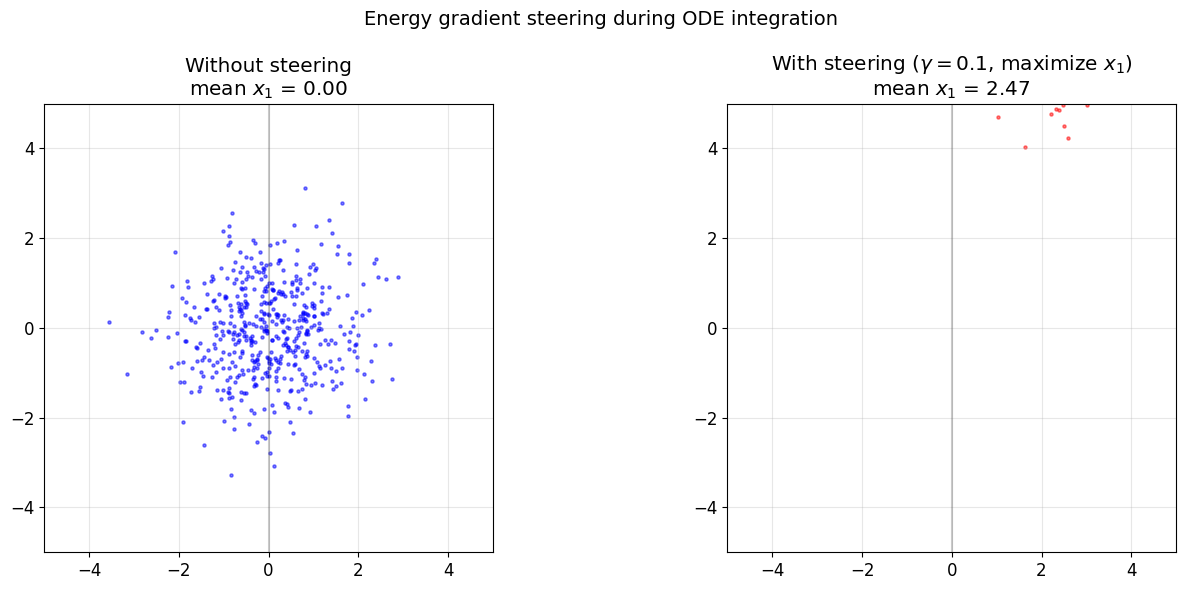

In [18]:
# Example: steering particles toward higher x-values using an energy gradient
# "Energy" = -mean(x_1) (negative because we want to MAXIMIZE x_1)

def property_energy(x):
    """Energy = -x_1 (to maximize the first coordinate)."""
    return -x[:, 0:1]

def property_gradient(x):
    """Gradient of energy w.r.t. x."""
    x = x.clone().requires_grad_(True)
    E = property_energy(x).sum()
    E.backward()
    return x.grad.detach()

# Simulate: base velocity (circular motion) + steering
def base_velocity(x, t):
    """Simple circular velocity field."""
    return torch.stack([-x[:, 1], x[:, 0]], dim=1) * 0.5

torch.manual_seed(42)
n_pts = 500
x_init = torch.randn(n_pts, 2)

# Without steering
x_no_steer = x_init.clone()
# With steering
x_steered = x_init.clone()
gamma = 0.1

dt = 0.05
for step in range(100):
    t = step * dt
    v = base_velocity(x_no_steer, t)
    x_no_steer = x_no_steer + v * dt
    
    v_s = base_velocity(x_steered, t)
    grad_E = property_gradient(x_steered)
    x_steered = x_steered + v_s * dt - gamma * grad_E  # subtract because we minimize E = -x1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(x_no_steer[:, 0].numpy(), x_no_steer[:, 1].numpy(), s=5, alpha=0.5, c='blue')
ax1.set_title(f'Without steering\nmean $x_1$ = {x_no_steer[:, 0].mean():.2f}')
ax1.set_xlim(-5, 5); ax1.set_ylim(-5, 5)
ax1.axvline(x=0, color='k', alpha=0.2); ax1.set_aspect('equal'); ax1.grid(True, alpha=0.3)

ax2.scatter(x_steered[:, 0].numpy(), x_steered[:, 1].numpy(), s=5, alpha=0.5, c='red')
ax2.set_title(f'With steering ($\\gamma={gamma}$, maximize $x_1$)\nmean $x_1$ = {x_steered[:, 0].mean():.2f}')
ax2.set_xlim(-5, 5); ax2.set_ylim(-5, 5)
ax2.axvline(x=0, color='k', alpha=0.2); ax2.set_aspect('equal'); ax2.grid(True, alpha=0.3)

plt.suptitle('Energy gradient steering during ODE integration', fontsize=14)
plt.tight_layout()
plt.show()

---
# Part 4: Stochastic Differential Equations (SDEs)

## 4.1 From ODEs to SDEs

In notebook 0a, we solved **ordinary differential equations** (ODEs):

$$\frac{d\mathbf{x}}{dt} = f(\mathbf{x}, t) \quad \text{(deterministic)}$$

A **stochastic differential equation** (SDE) adds randomness:

$$d\mathbf{x} = f(\mathbf{x}, t) \, dt + g(t) \, d\mathbf{W}$$

- $f(\mathbf{x}, t)$: **drift** coefficient (deterministic push)
- $g(t)$: **diffusion** coefficient (noise strength)
- $d\mathbf{W}$: **Wiener process** (Brownian motion) increment

Diffusion models are fundamentally SDEs: the forward process is an SDE that adds noise, and the reverse process is an SDE (or ODE) that removes noise.

## 4.2 Brownian motion (Wiener process)

A **Wiener process** $W(t)$ is a continuous random process where:
- $W(0) = 0$
- Increments $W(t + \Delta t) - W(t) \sim \mathcal{N}(0, \Delta t)$
- Increments over non-overlapping intervals are independent

It's the mathematical model for Brownian motion — the random jiggling of particles.

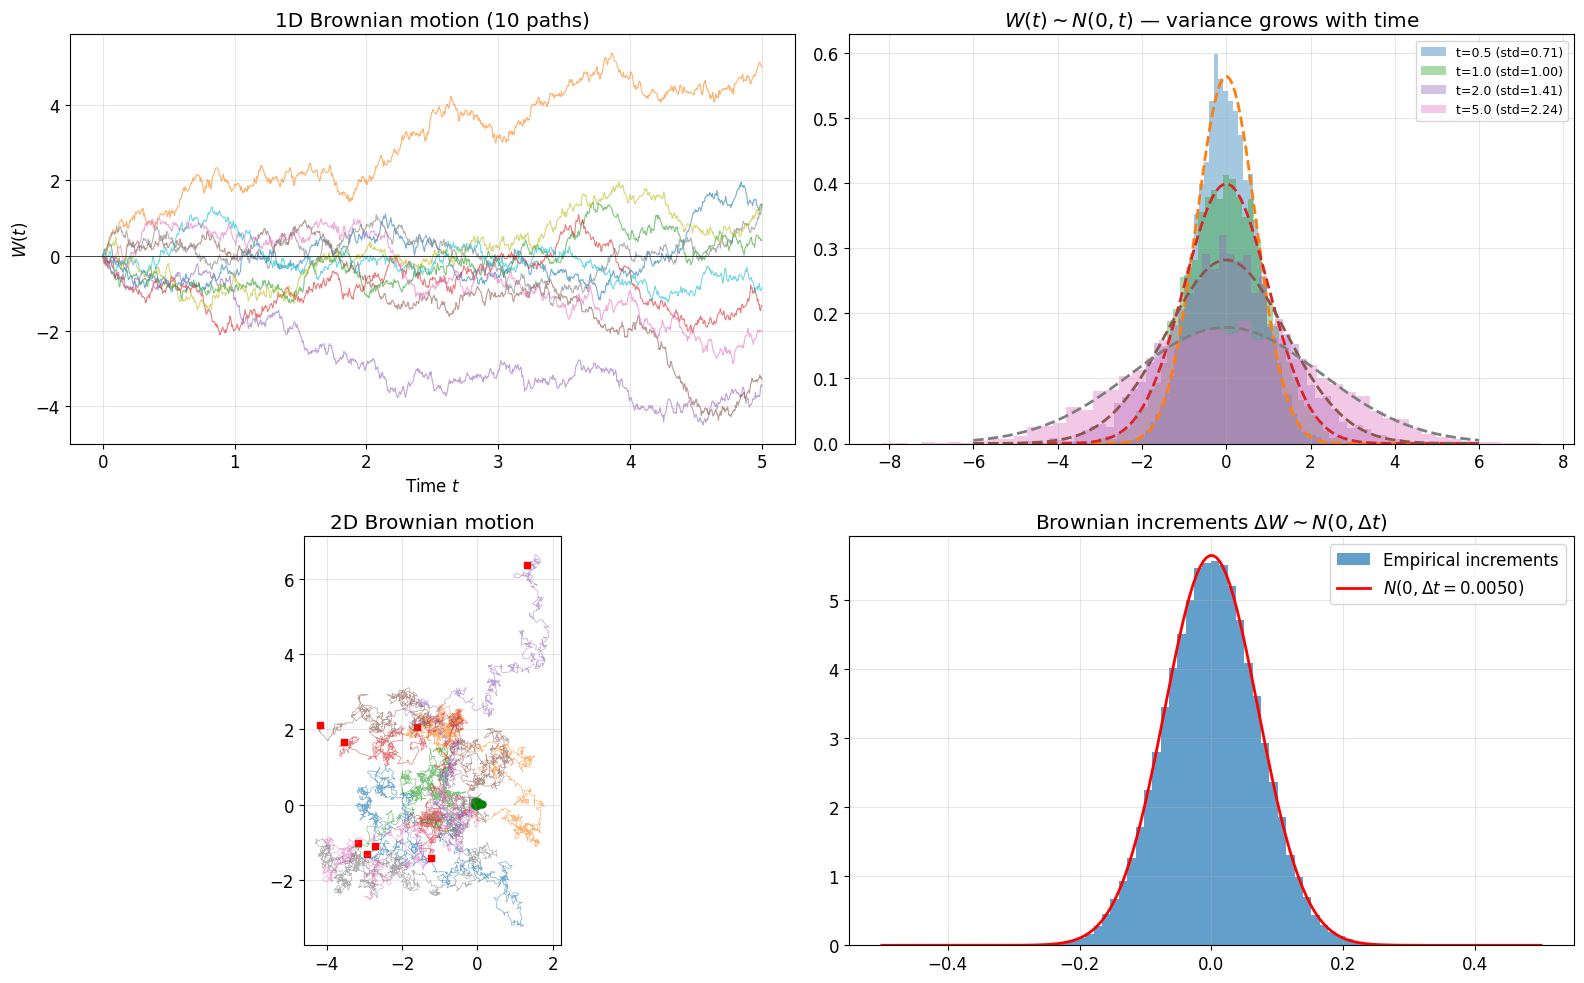

In [19]:
# Simulate and visualize Brownian motion
np.random.seed(42)
T = 5.0
n_steps = 1000
dt = T / n_steps
t = np.linspace(0, T, n_steps + 1)

# 1D Brownian motion
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Multiple 1D paths
for i in range(10):
    dW = np.random.randn(n_steps) * np.sqrt(dt)
    W = np.concatenate([[0], np.cumsum(dW)])
    axes[0, 0].plot(t, W, alpha=0.6, linewidth=0.8)
axes[0, 0].set_xlabel('Time $t$'); axes[0, 0].set_ylabel('$W(t)$')
axes[0, 0].set_title('1D Brownian motion (10 paths)')
axes[0, 0].axhline(y=0, color='k', linewidth=0.5)
axes[0, 0].grid(True, alpha=0.3)

# Distribution of W(t) at different times
n_samples = 5000
times_to_check = [0.5, 1.0, 2.0, 5.0]
for t_check in times_to_check:
    n_steps_t = int(t_check / dt)
    endpoints = []
    for _ in range(n_samples):
        dW = np.random.randn(n_steps_t) * np.sqrt(dt)
        endpoints.append(np.sum(dW))
    endpoints = np.array(endpoints)
    axes[0, 1].hist(endpoints, bins=50, alpha=0.4, density=True,
                     label=f't={t_check} (std={np.sqrt(t_check):.2f})')
    # Theoretical: N(0, t)
    x_line = np.linspace(-6, 6, 200)
    axes[0, 1].plot(x_line, scipy_norm.pdf(x_line, 0, np.sqrt(t_check)), '--', linewidth=2)

axes[0, 1].set_title('$W(t) \\sim N(0, t)$ — variance grows with time')
axes[0, 1].legend(fontsize=9); axes[0, 1].grid(True, alpha=0.3)

# 2D Brownian motion
for i in range(8):
    dWx = np.random.randn(n_steps) * np.sqrt(dt)
    dWy = np.random.randn(n_steps) * np.sqrt(dt)
    Wx = np.cumsum(dWx)
    Wy = np.cumsum(dWy)
    axes[1, 0].plot(Wx, Wy, alpha=0.6, linewidth=0.5)
    axes[1, 0].plot(Wx[0], Wy[0], 'go', markersize=5)
    axes[1, 0].plot(Wx[-1], Wy[-1], 'rs', markersize=5)
axes[1, 0].set_title('2D Brownian motion')
axes[1, 0].set_aspect('equal'); axes[1, 0].grid(True, alpha=0.3)

# Show that increments are Gaussian
dW_all = np.random.randn(100000) * np.sqrt(dt)
axes[1, 1].hist(dW_all, bins=50, density=True, alpha=0.7, label='Empirical increments')
x_line = np.linspace(-0.5, 0.5, 200)
axes[1, 1].plot(x_line, scipy_norm.pdf(x_line, 0, np.sqrt(dt)), 'r-', linewidth=2,
                 label=f'$N(0, \\Delta t={dt:.4f})$')
axes[1, 1].set_title('Brownian increments $\\Delta W \\sim N(0, \\Delta t)$')
axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4.3 Simulating SDEs: Euler-Maruyama method

The **Euler-Maruyama method** is the SDE equivalent of Euler's method for ODEs:

$$\mathbf{x}_{n+1} = \mathbf{x}_n + f(\mathbf{x}_n, t_n) \Delta t + g(t_n) \sqrt{\Delta t} \cdot \mathbf{z}_n, \quad \mathbf{z}_n \sim \mathcal{N}(0, I)$$

Compare to the ODE Euler method: $x_{n+1} = x_n + f(x_n, t_n) \Delta t$. The only addition is the noise term!

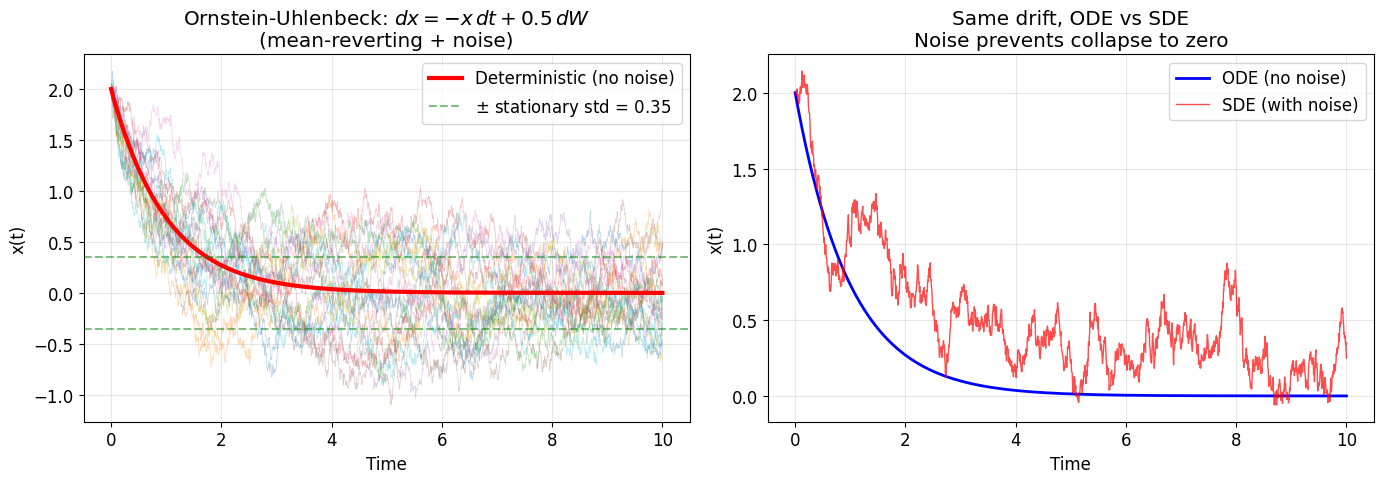

In [20]:
def euler_maruyama(drift_fn, diffusion_fn, x0, t_span, n_steps):
    """
    Solve SDE: dx = f(x, t)dt + g(t)dW using Euler-Maruyama.
    
    drift_fn: f(x, t) -> drift vector
    diffusion_fn: g(t) -> scalar diffusion coefficient  
    x0: initial condition (numpy array)
    t_span: (t_start, t_end)
    n_steps: number of steps
    """
    t_start, t_end = t_span
    dt = (t_end - t_start) / n_steps
    sqrt_dt = np.sqrt(abs(dt))
    
    x = np.array(x0, dtype=float)
    trajectory = [x.copy()]
    t = t_start
    
    for _ in range(n_steps):
        f = drift_fn(x, t)
        g = diffusion_fn(t)
        dW = np.random.randn(*x.shape) * sqrt_dt
        x = x + f * dt + g * dW
        t += dt
        trajectory.append(x.copy())
    
    return np.array(trajectory)

# Example 1: Ornstein-Uhlenbeck process (mean-reverting SDE)
# dx = -theta * x * dt + sigma * dW
# This is like a spring pulling x toward 0, plus noise
theta = 1.0
sigma_ou = 0.5

drift_ou = lambda x, t: -theta * x
diffusion_ou = lambda t: sigma_ou

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Multiple paths
for i in range(20):
    traj = euler_maruyama(drift_ou, diffusion_ou, [2.0], (0, 10), 2000)
    t_arr = np.linspace(0, 10, 2001)
    ax1.plot(t_arr, traj[:, 0], alpha=0.3, linewidth=0.5)

# Deterministic solution (no noise): x(t) = x0 * exp(-theta*t)
ax1.plot(t_arr, 2.0 * np.exp(-theta * t_arr), 'r-', linewidth=3, label='Deterministic (no noise)')
# Stationary distribution: N(0, sigma^2 / (2*theta))
stat_std = sigma_ou / np.sqrt(2 * theta)
ax1.axhline(y=stat_std, color='green', linestyle='--', alpha=0.5)
ax1.axhline(y=-stat_std, color='green', linestyle='--', alpha=0.5, label=f'$\\pm$ stationary std = {stat_std:.2f}')
ax1.set_xlabel('Time'); ax1.set_ylabel('x(t)')
ax1.set_title('Ornstein-Uhlenbeck: $dx = -x \\, dt + 0.5 \\, dW$\n(mean-reverting + noise)')
ax1.legend(); ax1.grid(True, alpha=0.3)

# Comparison: ODE vs SDE with same drift
traj_ode = [2.0]
traj_sde = euler_maruyama(drift_ou, diffusion_ou, [2.0], (0, 10), 2000)
x_ode = 2.0
dt_ode = 10.0 / 2000
for _ in range(2000):
    x_ode = x_ode + drift_ou(x_ode, 0) * dt_ode
    traj_ode.append(x_ode)

ax2.plot(t_arr, traj_ode, 'b-', linewidth=2, label='ODE (no noise)')
ax2.plot(t_arr, traj_sde[:, 0], 'r-', linewidth=1, alpha=0.7, label='SDE (with noise)')
ax2.set_xlabel('Time'); ax2.set_ylabel('x(t)')
ax2.set_title('Same drift, ODE vs SDE\nNoise prevents collapse to zero')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4.4 2D SDEs: particles in a potential with noise

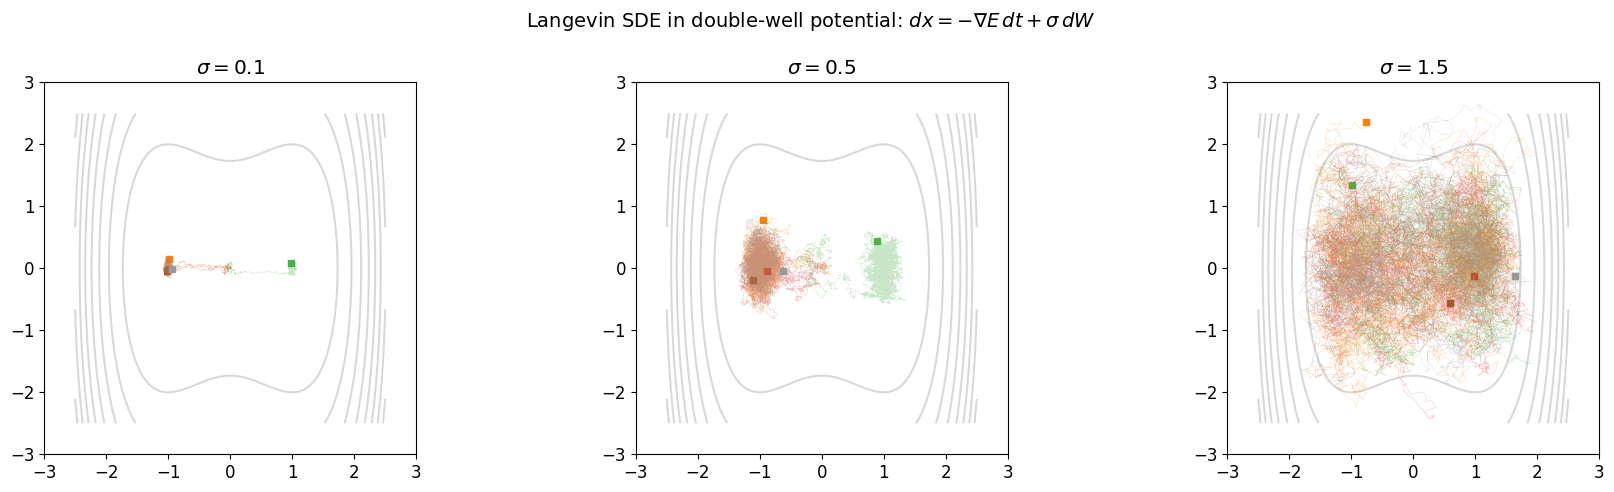

In [21]:
# 2D SDE: particles in the double-well potential + noise
# dx = -grad(E) dt + sigma dW (= Langevin dynamics!)

def double_well_drift(x, t):
    """Drift = -grad(E) where E = (x1^2-1)^2 + x2^2"""
    grad_E = np.array([
        4 * x[0] * (x[0]**2 - 1),
        2 * x[1]
    ])
    return -grad_E

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Different noise levels
for ax, sigma_val in zip(axes, [0.1, 0.5, 1.5]):
    diffusion = lambda t, s=sigma_val: s
    
    # Background energy contours
    ax.contour(X, Y, E, levels=10, colors='gray', alpha=0.3)
    
    # Simulate 5 particles
    colors = plt.cm.Set1(np.linspace(0, 1, 5))
    for i in range(5):
        np.random.seed(i + 100)
        traj = euler_maruyama(double_well_drift, diffusion, [0.0, 0.0], (0, 20), 5000)
        ax.plot(traj[:, 0], traj[:, 1], '-', color=colors[i], alpha=0.3, linewidth=0.3)
        ax.plot(traj[-1, 0], traj[-1, 1], 's', color=colors[i], markersize=5)
    
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
    ax.set_title(f'$\\sigma = {sigma_val}$')
    ax.set_aspect('equal')

plt.suptitle('Langevin SDE in double-well potential: $dx = -\\nabla E \\, dt + \\sigma \\, dW$', fontsize=14)
plt.tight_layout()
plt.show()

**Low noise** ($\sigma=0.1$): Particles get trapped in one well. **High noise** ($\sigma=1.5$): Particles can jump between wells but are less concentrated. This is the same tradeoff as annealed Langevin dynamics in notebook 0b!

## 4.5 The VP-SDE (Variance-Preserving SDE)

Notebook 7 introduces the **VP-SDE** formulation from [Song et al., 2021]. The forward (noising) SDE is:

$$d\mathbf{x} = -\frac{1}{2} \beta(t) \mathbf{x} \, dt + \sqrt{\beta(t)} \, d\mathbf{W}$$

where $\beta(t) = \beta_{\min} + t(\beta_{\max} - \beta_{\min})$ is a linear schedule. It is an Ornstein–Uhlenbeck process with drift coefficient $\beta/2$ and noise variance $\beta$, so its stationary distribution is $\mathcal{N}(0, \beta / (2 \cdot \beta/2)) = \mathcal{N}(0, I)$.

This SDE has the nice property that at any time $t$, we can directly compute the marginal distribution:

$$\mathbf{x}(t) | \mathbf{x}(0) \sim \mathcal{N}\left(\sqrt{1 - \sigma^2(t)} \cdot \mathbf{x}(0), \; \sigma^2(t) \cdot I\right)$$

where $\sigma^2(t) = 1 - \exp\left(-\int_0^t \beta(s) ds\right)$.

At $t=0$: $\sigma^2 = 0$, so $x(0) = x_0$ (clean data). As $\int_0^t \beta$ grows, $\sigma^2 \to 1$ and $x \to \mathcal{N}(0, I)$ (pure noise).

### It is exactly DDPM in continuous time

Take DDPM with $N$ steps and set $t_i = i/N$. For small $\beta_i$, $\prod_i (1-\beta_i) \approx \exp(-\sum_i \beta_i)$, and $\sum_i \beta_i \approx \int_0^t N\beta_{\text{DDPM}}(s)\,ds$. So the VP-SDE with $\beta(t) = N \cdot \beta^{\text{DDPM}}_{tN}$ reproduces DDPM. With the standard $N = 1000$ and `linspace(1e-4, 0.02, 1000)`:

$$\beta_{\min} = 1000 \times 10^{-4} = 0.1, \qquad \beta_{\max} = 1000 \times 0.02 = 20$$

These are exactly the VP-SDE constants used in notebook 7 and in Song et al. Notebooks 1 and 7 actually *train and sample* with the discrete schedule and only $T = 200$–$300$ steps, which corresponds to a much smaller effective $\beta_{\max}$ ($4$–$6$) and does not reach pure noise (see 3b §2.1). The plot below shows this.

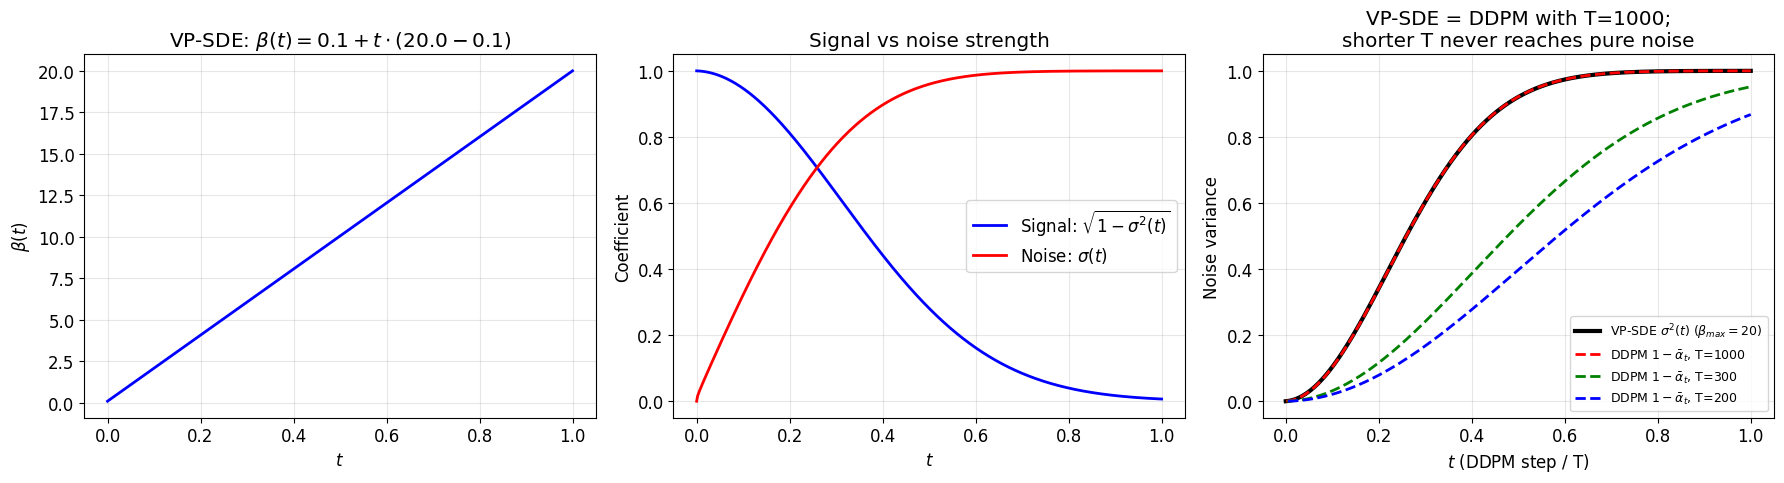

In [22]:
# VP-SDE noise schedule
beta_min = 0.1
beta_max = 20.0

def beta_t(t):
    # Linear beta schedule.
    return beta_min + t * (beta_max - beta_min)

def marginal_b(t):
    # Integral of beta(s) from 0 to t.
    return beta_min * t + 0.5 * t**2 * (beta_max - beta_min)

def sigma_squared(t):
    # Marginal variance at time t.
    return 1 - np.exp(-marginal_b(t))

def signal_coeff(t):
    # Signal coefficient sqrt(1 - sigma^2(t)).
    return np.sqrt(1 - sigma_squared(t))

t_range = np.linspace(0, 1, 500)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Beta schedule
axes[0].plot(t_range, [beta_t(t) for t in t_range], 'b-', linewidth=2)
axes[0].set_xlabel('$t$'); axes[0].set_ylabel('$\\beta(t)$')
axes[0].set_title(f'VP-SDE: $\\beta(t) = {beta_min} + t \\cdot ({beta_max} - {beta_min})$')
axes[0].grid(True, alpha=0.3)

# Noise schedule
sigma_sq = [sigma_squared(t) for t in t_range]
signal = [signal_coeff(t) for t in t_range]
axes[1].plot(t_range, signal, 'b-', linewidth=2, label='Signal: $\\sqrt{1 - \\sigma^2(t)}$')
axes[1].plot(t_range, np.sqrt(sigma_sq), 'r-', linewidth=2, label='Noise: $\\sigma(t)$')
axes[1].set_xlabel('$t$'); axes[1].set_ylabel('Coefficient')
axes[1].set_title('Signal vs noise strength')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Compare VP-SDE continuous schedule with the discrete DDPM schedule for several T
axes[2].plot(t_range, sigma_sq, 'k-', linewidth=3, label='VP-SDE $\\sigma^2(t)$ ($\\beta_{max}=20$)')
for T_discrete, style in [(1000, 'r--'), (300, 'g--'), (200, 'b--')]:
    alpha_bars_ddpm = np.cumprod(1 - np.linspace(1e-4, 0.02, T_discrete))
    t_discrete = np.arange(1, T_discrete + 1) / T_discrete
    axes[2].plot(t_discrete, 1 - alpha_bars_ddpm, style, linewidth=2, label=f'DDPM $1 - \\bar{{\\alpha}}_t$, T={T_discrete}')
axes[2].set_xlabel('$t$ (DDPM step / T)'); axes[2].set_ylabel('Noise variance')
axes[2].set_title('VP-SDE = DDPM with T=1000;\nshorter T never reaches pure noise')
axes[2].legend(fontsize=9); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

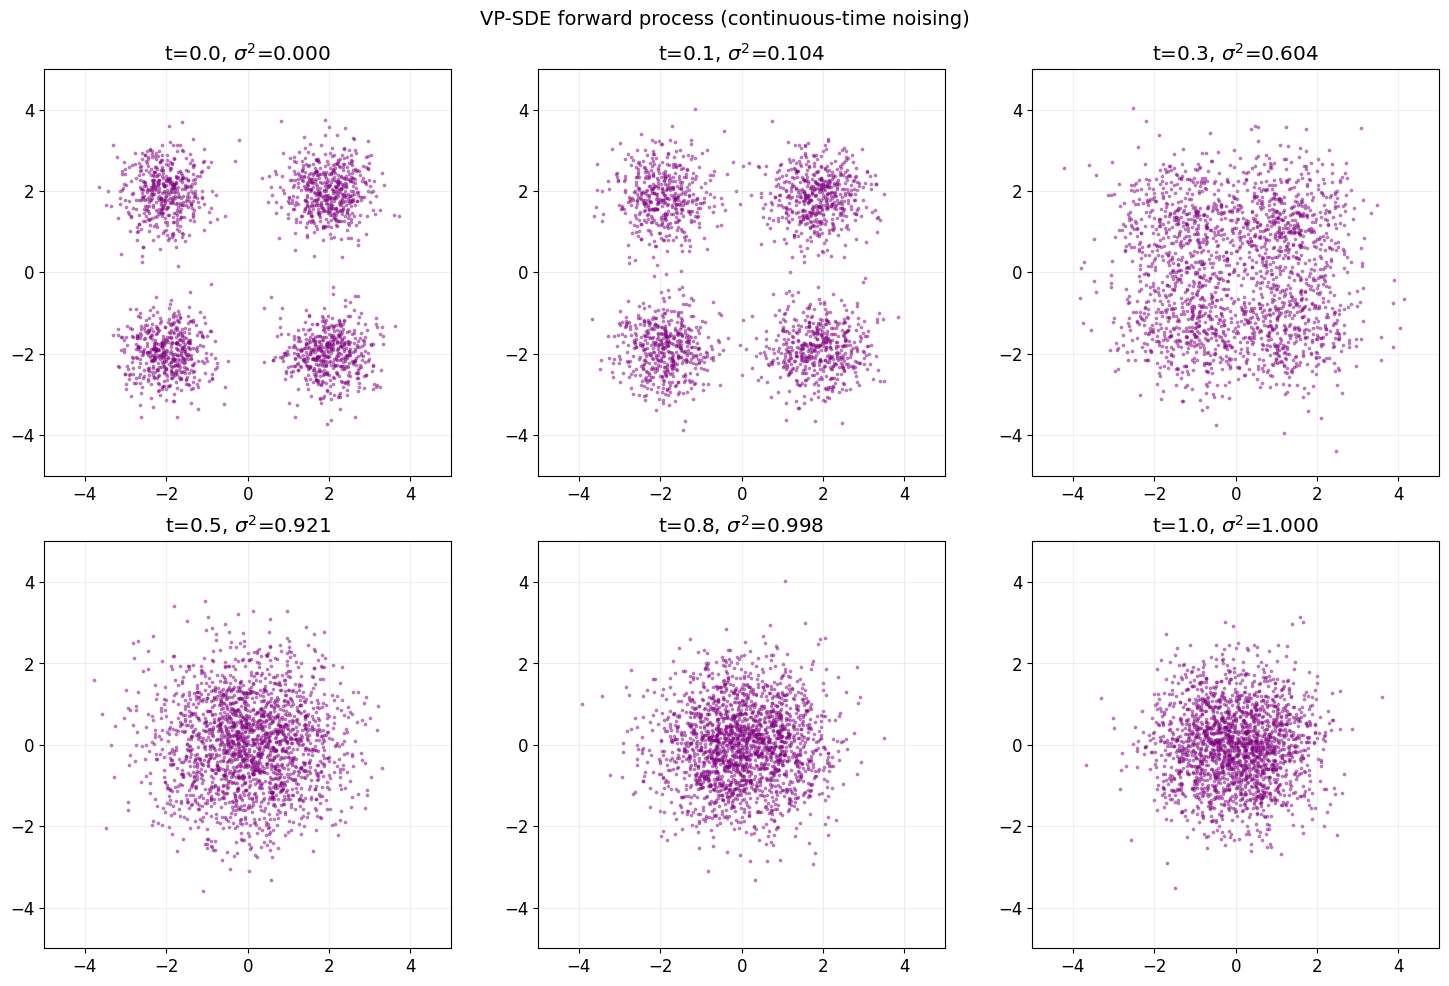

In [23]:
# Simulate the VP-SDE forward process on 2D data
# Generate mixture data
np.random.seed(42)
mixture_params = [
    {'mean': [2, 2], 'cov': [[0.3, 0], [0, 0.3]], 'weight': 0.25},
    {'mean': [-2, 2], 'cov': [[0.3, 0], [0, 0.3]], 'weight': 0.25},
    {'mean': [2, -2], 'cov': [[0.3, 0], [0, 0.3]], 'weight': 0.25},
    {'mean': [-2, -2], 'cov': [[0.3, 0], [0, 0.3]], 'weight': 0.25},
]

def sample_mixture(params, n):
    samples = []
    weights = [p['weight'] for p in params]
    indices = np.random.choice(len(params), size=n, p=weights)
    for i in range(n):
        p = params[indices[i]]
        samples.append(np.random.multivariate_normal(p['mean'], p['cov']))
    return np.array(samples, dtype=np.float32)

x0 = sample_mixture(mixture_params, 2000)

# Forward diffusion using the closed-form marginal
times_to_show = [0, 0.1, 0.3, 0.5, 0.8, 1.0]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, t in zip(axes.flat, times_to_show):
    if t == 0:
        x_t = x0
    else:
        s2 = sigma_squared(t)
        sc = signal_coeff(t)
        eps = np.random.randn(*x0.shape).astype(np.float32)
        x_t = sc * x0 + np.sqrt(s2) * eps
    
    ax.scatter(x_t[:, 0], x_t[:, 1], s=3, alpha=0.4, c='purple')
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
    s2_val = sigma_squared(t) if t > 0 else 0
    ax.set_title(f't={t:.1f}, $\\sigma^2$={s2_val:.3f}')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

plt.suptitle('VP-SDE forward process (continuous-time noising)', fontsize=14)
plt.tight_layout()
plt.show()

## 4.6 Forward and reverse SDEs

The remarkable result from [Anderson, 1982]: for a forward SDE, there exists a **reverse-time SDE** whose solutions have the same marginals $p_t$, run backward:

**Forward**: $d\mathbf{x} = f(\mathbf{x}, t) \, dt + g(t) \, d\mathbf{W}$

**Reverse** (time runs from $T$ down to $0$): $d\mathbf{x} = \left[f(\mathbf{x}, t) - g(t)^2 \nabla_x \log p_t(\mathbf{x})\right] dt + g(t) \, d\bar{\mathbf{W}}$

The reverse SDE depends on the **score function** $\nabla_x \log p_t(x)$ at each noise level $t$. This is what the diffusion model's neural network learns!

There's also a deterministic **probability flow ODE** (Song et al., 2021; no noise in reverse):

$$d\mathbf{x} = \left[f(\mathbf{x}, t) - \frac{1}{2} g(t)^2 \nabla_x \log p_t(\mathbf{x})\right] dt$$

It has the **same marginals** $p_t$ at every $t$ as the forward SDE, but each sample follows a smooth deterministic path. Both the reverse SDE and the probability-flow ODE generate valid samples. The ODE version is what DDIM sampling discretises (3b), and it is the bridge to flow matching. §4.7–4.8 below check both claims numerically.

In the demo below we use a milder schedule ($\beta_{\max} = 5$) so the forward process is easy to see. With it, $p_{t=1}$ is **not** close to $\mathcal{N}(0,1)$ (the signal coefficient is still $e^{-B(1)/2} \approx 0.28$), so we start the reverse process from the *exact* $p_1$. Starting from $\mathcal{N}(0,1)$ instead would bias the result. This is the same issue as DDPM with too few steps (§4.5).

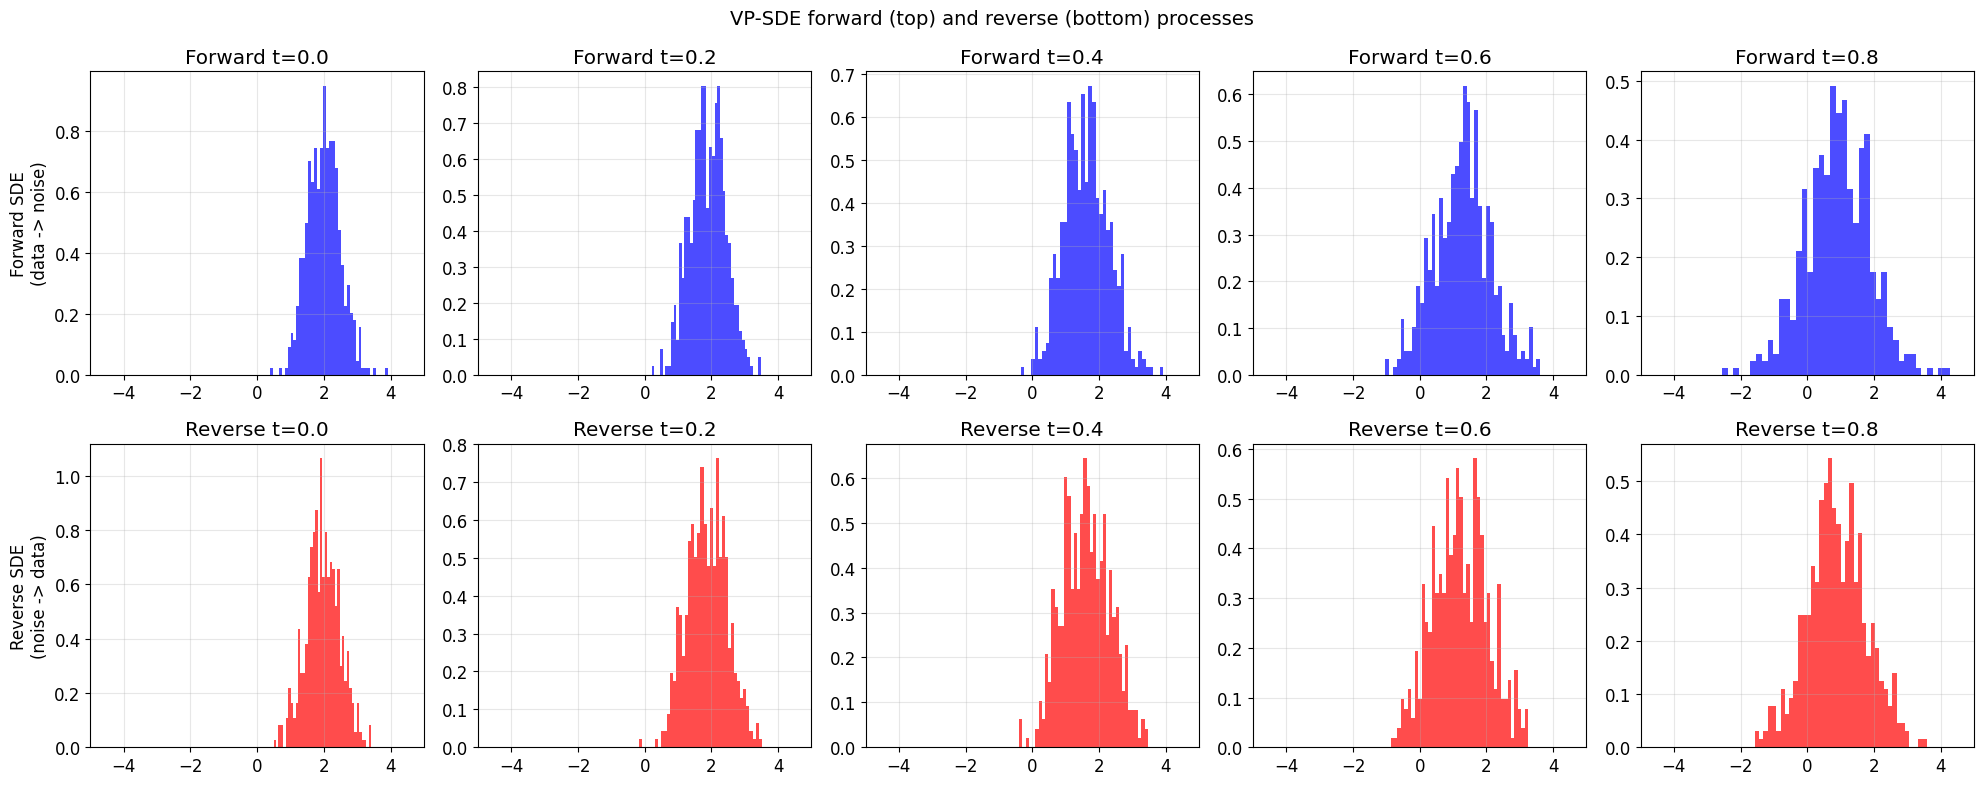

In [24]:
# Demonstrate forward SDE and reverse SDE for a simple 1D case
# Forward: dx = -0.5*beta(t)*x dt + sqrt(beta(t)) dW (VP-SDE)
# We know the score for the noised Gaussian analytically

# Start with data from N(2, 0.5^2)
mu_data, sigma_data = 2.0, 0.5

# VP-SDE parameters (mild for visualization)
beta_min_demo = 0.1
beta_max_demo = 5.0

def beta_demo(t):
    return beta_min_demo + t * (beta_max_demo - beta_min_demo)

def marginal_b_demo(t):
    return beta_min_demo * t + 0.5 * t**2 * (beta_max_demo - beta_min_demo)

def sigma_sq_demo(t):
    return 1 - np.exp(-marginal_b_demo(t))

# Forward SDE simulation
np.random.seed(42)
n_particles = 500
T_final = 1.0
n_steps = 500
dt = T_final / n_steps

x_forward = np.random.normal(mu_data, sigma_data, n_particles)  # start from data
forward_snapshots = [(0, x_forward.copy())]

for step in range(n_steps):
    t = step * dt
    b = beta_demo(t)
    drift = -0.5 * b * x_forward
    diffusion = np.sqrt(b)
    dW = np.random.randn(n_particles) * np.sqrt(dt)
    x_forward = x_forward + drift * dt + diffusion * dW
    if (step + 1) % 100 == 0:
        forward_snapshots.append(((step + 1) * dt, x_forward.copy()))

# Reverse SDE simulation (using analytical score)
# At time t, the marginal is N(mu*signal_coeff, sigma_data^2*signal_coeff^2 + sigma_sq)
# Score: -(x - mu*signal_coeff) / (sigma_data^2*signal_coeff^2 + sigma_sq)
# Start from the exact marginal p_1 (with beta_max = 5 it is NOT N(0,1); see the note above)
sc_T = np.sqrt(1 - sigma_sq_demo(T_final))
x_reverse = np.random.normal(mu_data * sc_T, np.sqrt(sigma_data**2 * sc_T**2 + sigma_sq_demo(T_final)), n_particles)
reverse_snapshots = [(T_final, x_reverse.copy())]

for step in range(n_steps):
    t = T_final - step * dt
    b = beta_demo(t)
    s2 = sigma_sq_demo(t)
    sc = np.sqrt(1 - s2)
    
    # Analytical score of the marginal
    marginal_mean = mu_data * sc
    marginal_var = sigma_data**2 * sc**2 + s2
    score = -(x_reverse - marginal_mean) / marginal_var
    
    # Reverse drift
    drift_fwd = -0.5 * b * x_reverse
    reverse_drift = drift_fwd - b * score  # f(x,t) - g^2 * score
    diffusion = np.sqrt(b)
    
    dW = np.random.randn(n_particles) * np.sqrt(dt)
    x_reverse = x_reverse - reverse_drift * dt + diffusion * dW  # note: going backward
    if (step + 1) % 100 == 0:
        reverse_snapshots.append((t - dt, x_reverse.copy()))

reverse_snapshots = reverse_snapshots[::-1]

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for idx in range(5):
    t_f, xf = forward_snapshots[idx]
    axes[0, idx].hist(xf, bins=40, density=True, alpha=0.7, color='blue')
    axes[0, idx].set_title(f'Forward t={t_f:.1f}')
    axes[0, idx].set_xlim(-5, 5); axes[0, idx].grid(True, alpha=0.3)
    if idx == 0:
        axes[0, idx].set_ylabel('Forward SDE\n(data -> noise)')

for idx in range(5):
    if idx < len(reverse_snapshots):
        t_r, xr = reverse_snapshots[idx]
        axes[1, idx].hist(xr, bins=40, density=True, alpha=0.7, color='red')
        axes[1, idx].set_title(f'Reverse t={t_r:.1f}')
        axes[1, idx].set_xlim(-5, 5); axes[1, idx].grid(True, alpha=0.3)
        if idx == 0:
            axes[1, idx].set_ylabel('Reverse SDE\n(noise -> data)')

plt.suptitle('VP-SDE forward (top) and reverse (bottom) processes', fontsize=14)
plt.tight_layout()
plt.show()

**Key takeaway**: The forward SDE gradually destroys the data distribution. The reverse SDE, guided by the score function, reconstructs it. In practice, a neural network approximates the score — and that's exactly what diffusion models do.

## 4.7 DDPM's sampling loop *is* a discretised reverse SDE

Notebook 1's reverse step is

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\Big) + \sqrt{\beta_t}\,z$$

Substitute the score, $\epsilon_\theta = -\sqrt{1-\bar\alpha_t}\, s_\theta$, and expand $1/\sqrt{1-\beta_t} \approx 1 + \beta_t/2$ for small $\beta_t$:

$$x_{t-1} \approx x_t + \underbrace{\tfrac{1}{2}\beta_t\, x_t + \beta_t\, s_\theta(x_t, t)}_{-[f - g^2 s]\,\Delta t} + \underbrace{\sqrt{\beta_t}\,z}_{g\sqrt{\Delta t}\,z}$$

With $f(x) = -\tfrac12\beta(t)x$, $g^2 = \beta(t)$ and $\beta_t = \beta(t)\Delta t$, this is exactly one **Euler–Maruyama step of the reverse VP-SDE**. So DDPM sampling is not Langevin MCMC (which runs at a *fixed* distribution, 0b §4). It is a numerical integration of Anderson's reverse-time SDE. Let's check by running both with the exact score of a 1D Gaussian dataset.

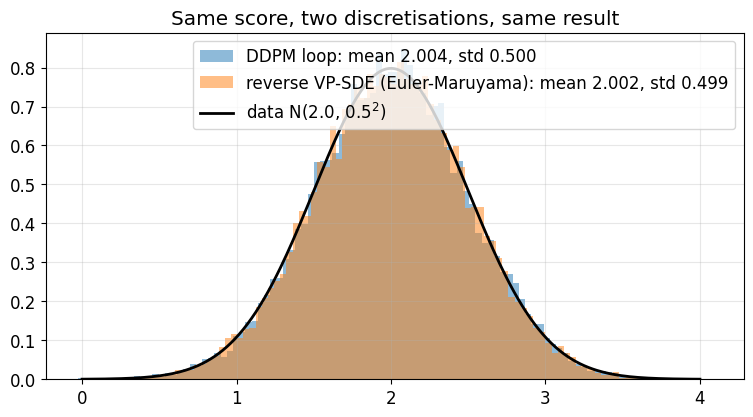

In [25]:
# Data N(mu, s^2); VP marginals are N(m(t) mu, m(t)^2 s^2 + 1 - m(t)^2) with m(t) = signal coefficient
mu_d, s_d = 2.0, 0.5
def exact_score_1d(x, m):
    return -(x - m * mu_d) / (m**2 * s_d**2 + 1 - m**2)

np.random.seed(0)
n = 20000
N = 1000

# (i) DDPM ancestral sampling, T = 1000, linear betas, exact score
betas_d = np.linspace(1e-4, 0.02, N)
alphas_d = 1 - betas_d
abar_d = np.cumprod(alphas_d)
x = np.random.randn(n)
for i in reversed(range(N)):
    s = exact_score_1d(x, np.sqrt(abar_d[i]))
    eps_hat = -np.sqrt(1 - abar_d[i]) * s
    z = np.random.randn(n) if i > 0 else 0.0
    x = (x - betas_d[i] / np.sqrt(1 - abar_d[i]) * eps_hat) / np.sqrt(alphas_d[i]) + np.sqrt(betas_d[i]) * z
x_ddpm = x

# (ii) Euler-Maruyama on the reverse VP-SDE, beta(t) in [0.1, 20], same number of steps
dt = 1.0 / N
x = np.random.randn(n)
for i in reversed(range(N)):
    t = (i + 1) * dt
    b = beta_t(t)
    s = exact_score_1d(x, signal_coeff(t))
    x = x - (-0.5 * b * x - b * s) * dt + np.sqrt(b * dt) * np.random.randn(n)
x_sde = x

grid = np.linspace(0, 4, 300)
plt.figure(figsize=(9, 4.5))
plt.hist(x_ddpm, bins=100, density=True, alpha=0.5, label=f'DDPM loop: mean {x_ddpm.mean():.3f}, std {x_ddpm.std():.3f}')
plt.hist(x_sde, bins=100, density=True, alpha=0.5, label=f'reverse VP-SDE (Euler-Maruyama): mean {x_sde.mean():.3f}, std {x_sde.std():.3f}')
plt.plot(grid, scipy_norm.pdf(grid, mu_d, s_d), 'k-', lw=2, label=f'data N({mu_d}, {s_d}$^2$)')
plt.legend(); plt.grid(alpha=0.3); plt.title('Same score, two discretisations, same result')
plt.show()

## 4.8 The probability-flow ODE: same marginals, no noise

Now drop the noise and halve the score term: $\frac{dx}{dt} = f(x,t) - \frac{1}{2}g(t)^2\,\nabla_x \log p_t(x)$, integrated from $t = 1$ down to $0$. Every particle follows a smooth deterministic path, yet the **distribution** of particles at each $t$ matches the SDE's. That is the whole point: randomness in the dynamics can be traded for a deterministic drift that knows the score.

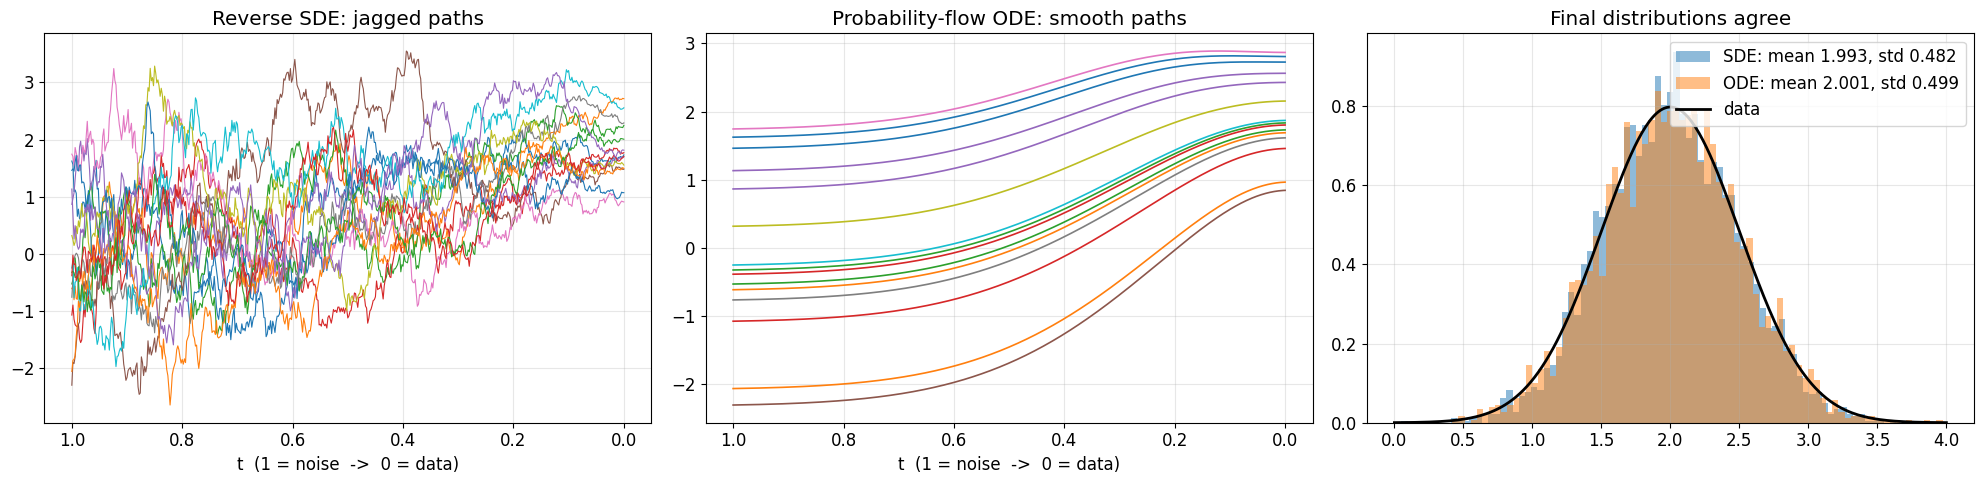

In [26]:
np.random.seed(1)
n_paths, N = 4000, 500
dt = 1.0 / N
x_sde = np.random.randn(n_paths); x_ode = x_sde.copy()
paths_sde, paths_ode = [x_sde[:15].copy()], [x_ode[:15].copy()]
for i in reversed(range(N)):
    t = (i + 1) * dt
    b, m = beta_t(t), signal_coeff(t)
    x_sde = x_sde - (-0.5 * b * x_sde - b * exact_score_1d(x_sde, m)) * dt + np.sqrt(b * dt) * np.random.randn(n_paths)
    x_ode = x_ode - (-0.5 * b * x_ode - 0.5 * b * exact_score_1d(x_ode, m)) * dt
    paths_sde.append(x_sde[:15].copy()); paths_ode.append(x_ode[:15].copy())
t_axis = np.linspace(1, 0, N + 1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].plot(t_axis, np.array(paths_sde), lw=0.8); axes[0].set_title('Reverse SDE: jagged paths')
axes[1].plot(t_axis, np.array(paths_ode), lw=1.2); axes[1].set_title('Probability-flow ODE: smooth paths')
for ax in axes[:2]:
    ax.invert_xaxis(); ax.set_xlabel('t  (1 = noise  ->  0 = data)'); ax.grid(alpha=0.3)
axes[2].hist(x_sde, bins=80, density=True, alpha=0.5, label=f'SDE: mean {x_sde.mean():.3f}, std {x_sde.std():.3f}')
axes[2].hist(x_ode, bins=80, density=True, alpha=0.5, label=f'ODE: mean {x_ode.mean():.3f}, std {x_ode.std():.3f}')
axes[2].plot(grid, scipy_norm.pdf(grid, mu_d, s_d), 'k-', lw=2, label='data')
axes[2].legend(); axes[2].grid(alpha=0.3); axes[2].set_title('Final distributions agree')
plt.tight_layout(); plt.show()

Notice how ODE paths *fan in* smoothly and **keep their ordering**: the ODE is a deterministic, invertible map from noise to data (and back). That invertibility is what makes exact likelihoods possible (0a §6.1) and what DDIM and flow matching exploit. Notebook 3b shows that the probability-flow ODE of DDPM and the flow-matching ODE are the same map run on different clocks.

---
# Part 5: Higher-Order Autograd

## 5.1 Why we need gradients through gradients

Several concepts in the later notebooks require **second-order derivatives**:

1. **Score matching loss** (notebook 7): The score $s_\theta(x) = -\nabla_x E_\theta(x)$ is itself a gradient. The loss $\|s_\theta - s_{\text{true}}\|^2$ requires differentiating *through* that gradient for backpropagation.

2. **Energy steering** (notebook 6): Computing $\nabla_x E(x)$ at inference time while the model's computation graph is active.

3. **Hessians**: Second derivatives measure curvature, important for understanding energy landscapes.

## 5.2 `create_graph=True`

By default, `torch.autograd.grad` detaches the result from the computation graph. To differentiate *through* a gradient computation, we need `create_graph=True`.

In [27]:
# Demonstration: computing gradients through gradients

# Simple example: f(x) = x^4
# f'(x) = 4x^3
# We want to minimize f'(x)^2 (make the gradient zero) by adjusting x

x = torch.tensor(2.0, requires_grad=True)

# Forward pass: compute f(x)
f = x**4

# First derivative (with create_graph=True to allow further differentiation)
df_dx = torch.autograd.grad(f, x, create_graph=True)[0]
print(f"x = {x.item():.1f}")
print(f"f(x) = x^4 = {f.item():.1f}")
print(f"f'(x) = 4x^3 = {df_dx.item():.1f}  (analytical: {4 * 2.0**3:.1f})")

# Now compute loss = f'(x)^2 and backpropagate
loss = df_dx**2
loss.backward()  # This requires create_graph=True above!

print(f"\nLoss = f'(x)^2 = {loss.item():.1f}")
print(f"d(loss)/dx = 2*f'(x)*f''(x) = {x.grad.item():.1f}")
print(f"  Analytical: 2*(4*2^3)*(12*2^2) = {2 * (4*8) * (12*4):.1f}")

x = 2.0
f(x) = x^4 = 16.0
f'(x) = 4x^3 = 32.0  (analytical: 32.0)

Loss = f'(x)^2 = 1024.0
d(loss)/dx = 2*f'(x)*f''(x) = 3072.0
  Analytical: 2*(4*2^3)*(12*2^2) = 3072.0


In [28]:
# Without create_graph=True, we'd get an error:
x = torch.tensor(2.0, requires_grad=True)
f = x**4

# This detaches from the graph:
df_dx_detached = torch.autograd.grad(f, x, create_graph=False)[0]
print(f"df/dx (detached) requires_grad: {df_dx_detached.requires_grad}")
print("Cannot backpropagate through this!")

# This maintains the graph:
x = torch.tensor(2.0, requires_grad=True)
f = x**4
df_dx_graph = torch.autograd.grad(f, x, create_graph=True)[0]
print(f"\ndf/dx (with graph) requires_grad: {df_dx_graph.requires_grad}")
print("CAN backpropagate through this!")

df/dx (detached) requires_grad: False
Cannot backpropagate through this!

df/dx (with graph) requires_grad: True
CAN backpropagate through this!


## 5.3 Computing Hessians

The **Hessian** is the matrix of second partial derivatives:

$$H_{ij} = \frac{\partial^2 f}{\partial x_i \partial x_j}$$

For energy functions, the Hessian tells us about the curvature of the energy landscape:
- Positive definite Hessian = local minimum (a "bowl")
- Negative eigenvalue = saddle point or maximum

In [29]:
# Compute Hessian of the double-well energy
# E(x,y) = (x^2 - 1)^2 + y^2
# Gradient: (4x(x^2-1), 2y)
# Hessian: [[12x^2 - 4, 0], [0, 2]]

def energy_torch(x):
    return (x[0]**2 - 1)**2 + x[1]**2

# At the minimum (1, 0)
x_min = torch.tensor([1.0, 0.0])
H_min = torch.autograd.functional.hessian(energy_torch, x_min)
print("Hessian at minimum (1, 0):")
print(H_min)
print(f"Eigenvalues: {torch.linalg.eigvalsh(H_min).numpy()}")
print("Both positive -> local minimum (confirmed!)\n")

# At the saddle point (0, 0)
x_saddle = torch.tensor([0.0, 0.0])
H_saddle = torch.autograd.functional.hessian(energy_torch, x_saddle)
print("Hessian at saddle point (0, 0):")
print(H_saddle)
print(f"Eigenvalues: {torch.linalg.eigvalsh(H_saddle).numpy()}")
print("One negative eigenvalue -> saddle point (confirmed!)\n")

# At an arbitrary point
x_arb = torch.tensor([0.5, 1.0])
H_arb = torch.autograd.functional.hessian(energy_torch, x_arb)
print(f"Hessian at (0.5, 1.0):")
print(H_arb)
print(f"Analytical: [[12*0.25 - 4, 0], [0, 2]] = [[-1, 0], [0, 2]]")

Hessian at minimum (1, 0):
tensor([[8., 0.],
        [0., 2.]])
Eigenvalues: [2. 8.]
Both positive -> local minimum (confirmed!)

Hessian at saddle point (0, 0):
tensor([[-4.,  0.],
        [ 0.,  2.]])
Eigenvalues: [-4.  2.]
One negative eigenvalue -> saddle point (confirmed!)

Hessian at (0.5, 1.0):
tensor([[-1.,  0.],
        [ 0.,  2.]])
Analytical: [[12*0.25 - 4, 0], [0, 2]] = [[-1, 0], [0, 2]]


## 5.4 Score matching with second-order gradients

In notebook 7, the energy network learns $E_\theta(x, t)$ and derives the score as $s_\theta(x) = -\nabla_x E_\theta(x, t)$. Training requires differentiating the loss through this gradient computation.

Here's a minimal example of this pattern:

In [30]:
# Learn an energy function whose negative gradient matches a target score

# Target: score of N(0, 1) in 2D, which is s(x) = -x
def target_score(x):
    return -x

# Energy network
class EnergyNet(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1),  # scalar energy output
        )
    
    def forward(self, x):
        return self.net(x).squeeze(-1)
    
    def score(self, x):
        """Compute score = -grad(E) using autograd."""
        x = x.clone().requires_grad_(True)
        E = self.forward(x).sum()
        grad_E = torch.autograd.grad(E, x, create_graph=True)[0]  # create_graph=True!
        return -grad_E  # score = -grad(E)

energy_net = EnergyNet().to(device)
optimizer_e = optim.Adam(energy_net.parameters(), lr=1e-3)

losses = []
for step in range(3000):
    # Sample random points
    x = torch.randn(256, 2).to(device)
    
    # Predicted score (involves autograd internally)
    s_pred = energy_net.score(x)
    
    # Target score
    s_target = target_score(x)
    
    # Loss: MSE between predicted and target scores
    loss = ((s_pred - s_target)**2).mean()
    
    # Backpropagate THROUGH the autograd computation in score()
    # This is where create_graph=True is essential!
    optimizer_e.zero_grad()
    loss.backward()
    optimizer_e.step()
    losses.append(loss.item())

print(f"Final score matching loss: {losses[-1]:.6f}")

Final score matching loss: 0.000007


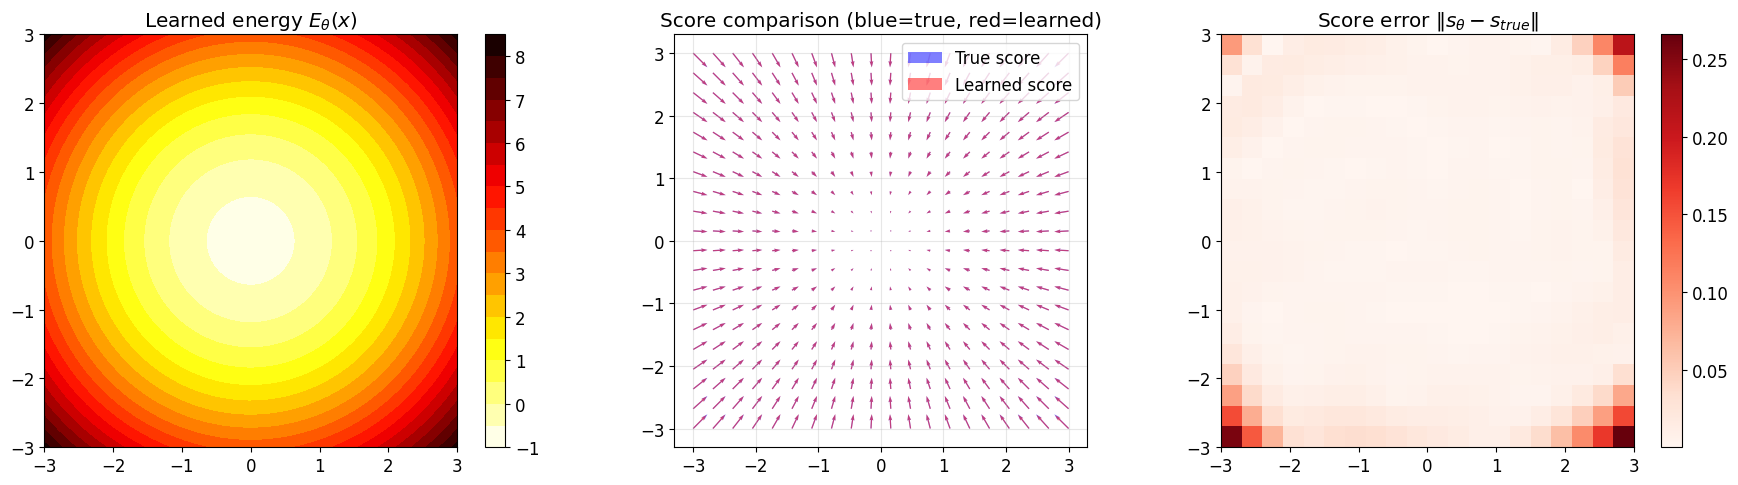

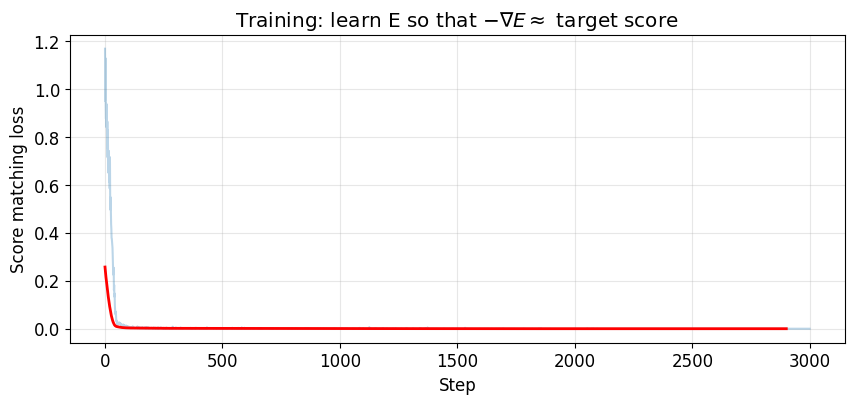

In [31]:
# Visualize the learned energy and score
energy_net.eval()

x_range = np.linspace(-3, 3, 100)
y_range = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x_range, y_range)
grid = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32).to(device)

with torch.no_grad():
    E_grid = energy_net(grid).cpu().numpy().reshape(X.shape)

# Score on coarser grid
x_q = np.linspace(-3, 3, 20)
y_q = np.linspace(-3, 3, 20)
Xq, Yq = np.meshgrid(x_q, y_q)
grid_q = torch.tensor(np.stack([Xq.ravel(), Yq.ravel()], axis=1), dtype=torch.float32).to(device)

s_learned = energy_net.score(grid_q).detach().cpu().numpy()
s_true = target_score(grid_q).cpu().numpy()

Sx_l = s_learned[:, 0].reshape(Xq.shape)
Sy_l = s_learned[:, 1].reshape(Yq.shape)
Sx_t = s_true[:, 0].reshape(Xq.shape)
Sy_t = s_true[:, 1].reshape(Yq.shape)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Learned energy
cs = axes[0].contourf(X, Y, E_grid, levels=20, cmap='hot_r')
axes[0].set_title('Learned energy $E_\\theta(x)$')
plt.colorbar(cs, ax=axes[0]); axes[0].set_aspect('equal')

# Learned score vs true score
axes[1].quiver(Xq, Yq, Sx_t, Sy_t, color='blue', alpha=0.5, label='True score')
axes[1].quiver(Xq, Yq, Sx_l, Sy_l, color='red', alpha=0.5, label='Learned score')
axes[1].set_title('Score comparison (blue=true, red=learned)')
axes[1].legend(); axes[1].set_aspect('equal'); axes[1].grid(True, alpha=0.3)

# Score error
error = np.sqrt((Sx_l - Sx_t)**2 + (Sy_l - Sy_t)**2)
im = axes[2].imshow(error, extent=[-3, 3, -3, 3], origin='lower', cmap='Reds')
axes[2].set_title('Score error $\\|s_\\theta - s_{true}\\|$')
plt.colorbar(im, ax=axes[2]); axes[2].set_aspect('equal')

plt.tight_layout()
plt.show()

# Training loss curve
plt.figure(figsize=(10, 4))
plt.plot(losses, alpha=0.3)
plt.plot(np.convolve(losses, np.ones(100)/100, mode='valid'), 'r-', linewidth=2)
plt.xlabel('Step'); plt.ylabel('Score matching loss')
plt.title('Training: learn E so that $-\\nabla E \\approx$ target score')
plt.grid(True, alpha=0.3)
plt.show()

## 5.5 Memory and computational cost

Computing gradients through gradients is expensive:
- The forward pass computation graph must be retained (memory)
- Backpropagation through the gradient adds extra operations
- This is why notebook 7's training is slower than standard diffusion

In [32]:
import time

# Compare computational cost: standard vs second-order gradients
net = nn.Sequential(nn.Linear(2, 128), nn.SiLU(), nn.Linear(128, 128),
                     nn.SiLU(), nn.Linear(128, 1)).to(device)
opt = optim.Adam(net.parameters(), lr=1e-3)

# Method 1: Standard (first-order) training
t0 = time.time()
for _ in range(500):
    x = torch.randn(256, 2, device=device)
    y = net(x).squeeze()
    loss = (y**2).mean()  # simple loss on output
    opt.zero_grad()
    loss.backward()
    opt.step()
t_first = time.time() - t0

# Method 2: Second-order (gradient through gradient) training
net2 = nn.Sequential(nn.Linear(2, 128), nn.SiLU(), nn.Linear(128, 128),
                      nn.SiLU(), nn.Linear(128, 1)).to(device)
opt2 = optim.Adam(net2.parameters(), lr=1e-3)

t0 = time.time()
for _ in range(500):
    x = torch.randn(256, 2, device=device, requires_grad=True)
    E = net2(x).sum()
    grad_E = torch.autograd.grad(E, x, create_graph=True)[0]  # first gradient
    loss = (grad_E**2).mean()  # loss on the gradient
    opt2.zero_grad()
    loss.backward()  # second gradient (through the first)
    opt2.step()
t_second = time.time() - t0

print(f"First-order training (500 steps):  {t_first:.2f}s")
print(f"Second-order training (500 steps): {t_second:.2f}s")
print(f"Slowdown factor: {t_second/t_first:.1f}x")
print(f"\nThis is why EBM training (notebook 7) is slower than standard diffusion.")

First-order training (500 steps):  0.18s
Second-order training (500 steps): 0.34s
Slowdown factor: 1.9x

This is why EBM training (notebook 7) is slower than standard diffusion.


## 5.6 Practical pattern: `enable_grad()` during inference

In notebook 6, gradient-based steering is applied at inference time (inside `torch.no_grad()` blocks). You need to temporarily re-enable gradients:

In [33]:
# Pattern used in notebook 6 for gradient-based steering
dummy_model = nn.Linear(2, 2).to(device)
dummy_model.eval()

def energy_property(x):
    """Some property we want to optimize (e.g., image brightness)."""
    return x.sum(dim=1)

x = torch.randn(10, 2, device=device)

# During inference (no_grad context for the model)
with torch.no_grad():
    # Model prediction (no gradients needed)
    velocity = dummy_model(x)
    
    # But for energy steering, we DO need gradients w.r.t. x
    with torch.enable_grad():  # temporarily re-enable
        x_grad = x.clone().requires_grad_(True)
        E = energy_property(x_grad)
        E.sum().backward()
        energy_gradient = x_grad.grad
    
    # Apply steering
    gamma = 0.1
    x_new = x + velocity * 0.01 + gamma * energy_gradient

print("Pattern: torch.no_grad() for model, torch.enable_grad() for energy gradient")
print(f"Energy gradient shape: {energy_gradient.shape}")
print(f"This lets us steer generation without building the full model computation graph.")

Pattern: torch.no_grad() for model, torch.enable_grad() for energy gradient
Energy gradient shape: torch.Size([10, 2])
This lets us steer generation without building the full model computation graph.


---
# Part 6: Denoising Score Matching (putting it all together)

This section ties together energy, score, SDE, and autograd into the training procedure used in notebook 7.

## 6.1 The idea

We want to learn an energy function $E_\theta(x, t)$ at every noise level. The training signal comes from the **denoising score matching** objective (0b §6):

1. Sample clean data $x_0$ and noise $\epsilon$
2. Compute noisy data $x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1-\bar{\alpha}_t} \epsilon$
3. The per-sample target is the score of the *conditional* $q(x_t \mid x_0)$: $-\epsilon / \sqrt{1-\bar{\alpha}_t}$. It is not the true marginal score, but its conditional mean is (Tweedie), and that is enough for regression.
4. The predicted score is $s_\theta = -\nabla_x E_\theta(x_t, t)$
5. Loss: $(1-\bar\alpha_t)\,\|s_\theta - s_{\text{target}}\|^2$

The weight $(1-\bar\alpha_t)$ makes this **identical to DDPM's $\epsilon$-loss**: with $\epsilon_\theta := -\sqrt{1-\bar\alpha_t}\,s_\theta$ it reads $\|\epsilon_\theta - \epsilon\|^2$. The only thing that differs from notebook 1 is that $\epsilon_\theta$ is constrained to be the gradient of a scalar.

Let's implement this for the 2D mixture data.

In [34]:
# Full denoising score matching with energy network

class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    
    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2
        emb = torch.log(torch.tensor(10000.0, device=device)) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = t.unsqueeze(1) * emb.unsqueeze(0)
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)


class TimeConditionedEnergyNet(nn.Module):
    def __init__(self, data_dim=2, time_dim=32, hidden_dim=128):
        super().__init__()
        self.time_embed = SinusoidalEmbedding(time_dim)
        self.time_mlp = nn.Sequential(
            nn.Linear(time_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )
        self.input_proj = nn.Linear(data_dim, hidden_dim)
        self.blocks = nn.ModuleList([
            nn.Sequential(
                nn.LayerNorm(hidden_dim),
                nn.Linear(hidden_dim, hidden_dim),
                nn.SiLU(),
                nn.Linear(hidden_dim, hidden_dim),
            ) for _ in range(3)
        ])
        # Output a vector whose squared norm is the energy (like notebook 7)
        self.output_proj = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Linear(hidden_dim, data_dim),
        )
    
    def forward(self, x, t):
        """Returns the r vector (energy = ||r||^2)."""
        t_emb = self.time_embed(t)
        t_emb = self.time_mlp(t_emb)
        h = self.input_proj(x) + t_emb
        for block in self.blocks:
            h = h + block(h)
        return self.output_proj(h)
    
    def compute_energy(self, x, t):
        r = self.forward(x, t)
        return (r**2).sum(dim=-1)
    
    def compute_score(self, x, t):
        """Score = -grad(E) via autograd."""
        x = x.clone().requires_grad_(True)
        E = self.compute_energy(x, t).sum()
        grad_E = torch.autograd.grad(E, x, create_graph=True)[0]
        return -grad_E

Step 1000: loss = 0.6380


Step 2000: loss = 0.6604


Step 3000: loss = 0.6703


Step 4000: loss = 0.6278


Step 5000: loss = 0.6097


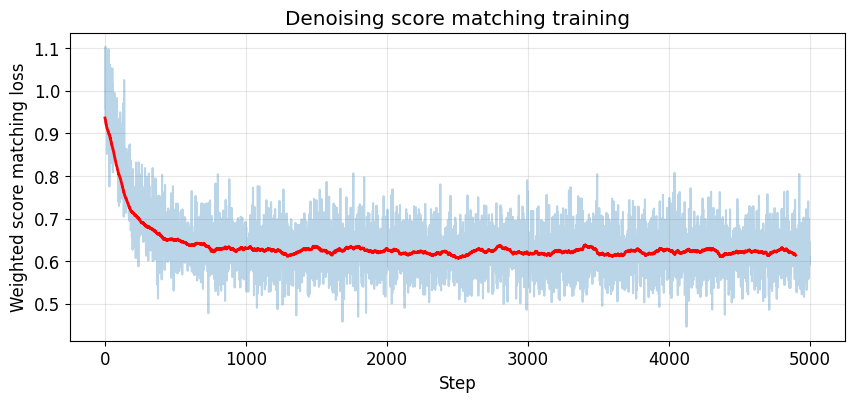

In [35]:
# Train with denoising score matching
data_dsm = torch.tensor(sample_mixture(mixture_params, 2000), dtype=torch.float32).to(device)

T_steps = 200
betas_dsm = torch.linspace(1e-4, 0.02, T_steps).to(device)
alphas_dsm = 1 - betas_dsm
alpha_bars_dsm = torch.cumprod(alphas_dsm, dim=0)

energy_model = TimeConditionedEnergyNet(data_dim=2, hidden_dim=128).to(device)
optimizer_dsm = optim.Adam(energy_model.parameters(), lr=1e-4)

losses_dsm = []
for step in range(5000):
    # Sample batch
    idx = torch.randint(0, len(data_dsm), (256,))
    x0 = data_dsm[idx]
    
    # Sample random timesteps
    t = torch.randint(0, T_steps, (256,), device=device)
    
    # Forward diffusion
    eps = torch.randn_like(x0)
    ab = alpha_bars_dsm[t].unsqueeze(1)
    xt = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * eps
    
    # Ground truth score
    noise_var = (1 - ab)
    s_true = -eps / torch.sqrt(noise_var)
    
    # Predicted score (involves autograd)
    s_pred = energy_model.compute_score(xt, t.float())
    
    # Weighted score matching loss
    loss = (noise_var * (s_pred - s_true)**2).mean()
    
    optimizer_dsm.zero_grad()
    loss.backward()
    optimizer_dsm.step()
    losses_dsm.append(loss.item())
    
    if (step + 1) % 1000 == 0:
        print(f"Step {step+1}: loss = {loss.item():.4f}")

plt.figure(figsize=(10, 4))
plt.plot(losses_dsm, alpha=0.3)
plt.plot(np.convolve(losses_dsm, np.ones(100)/100, mode='valid'), 'r-', linewidth=2)
plt.xlabel('Step'); plt.ylabel('Weighted score matching loss')
plt.title('Denoising score matching training')
plt.grid(True, alpha=0.3)
plt.show()

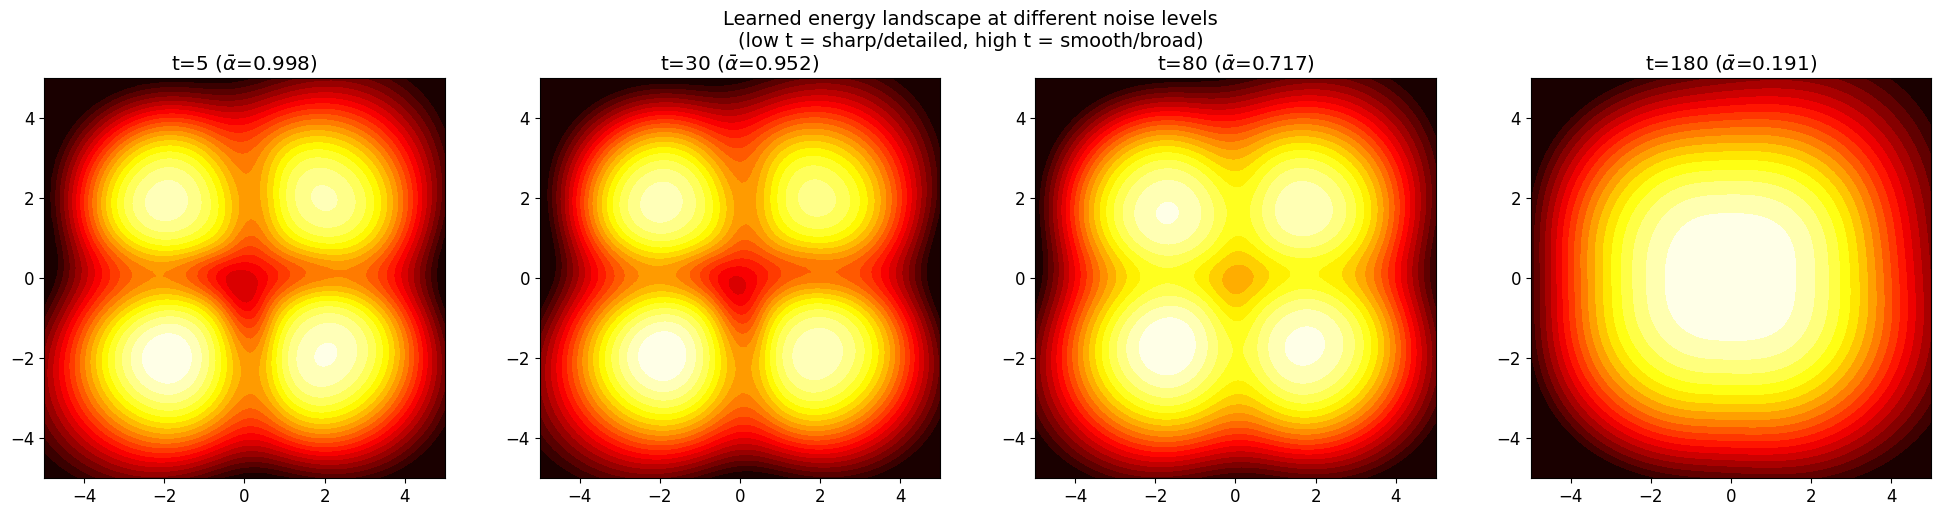

In [36]:
# Visualize the learned energy landscape at different timesteps
energy_model.eval()

x_range = np.linspace(-5, 5, 100)
y_range = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x_range, y_range)
grid_pts = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32).to(device)

timesteps_viz = [5, 30, 80, 180]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, t_val in zip(axes, timesteps_viz):
    t_tensor = torch.full((grid_pts.shape[0],), float(t_val), device=device)
    with torch.no_grad():
        E = energy_model.compute_energy(grid_pts, t_tensor).cpu().numpy().reshape(X.shape)
    
    # Clip for visualization
    E_clipped = np.clip(E, E.min(), np.percentile(E, 95))
    ax.contourf(X, Y, E_clipped, levels=20, cmap='hot_r')
    ax.set_title(f't={t_val} ($\\bar{{\\alpha}}$={alpha_bars_dsm[t_val].item():.3f})')
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
    ax.set_aspect('equal')

plt.suptitle('Learned energy landscape at different noise levels\n'
             '(low t = sharp/detailed, high t = smooth/broad)', fontsize=14)
plt.tight_layout()
plt.show()

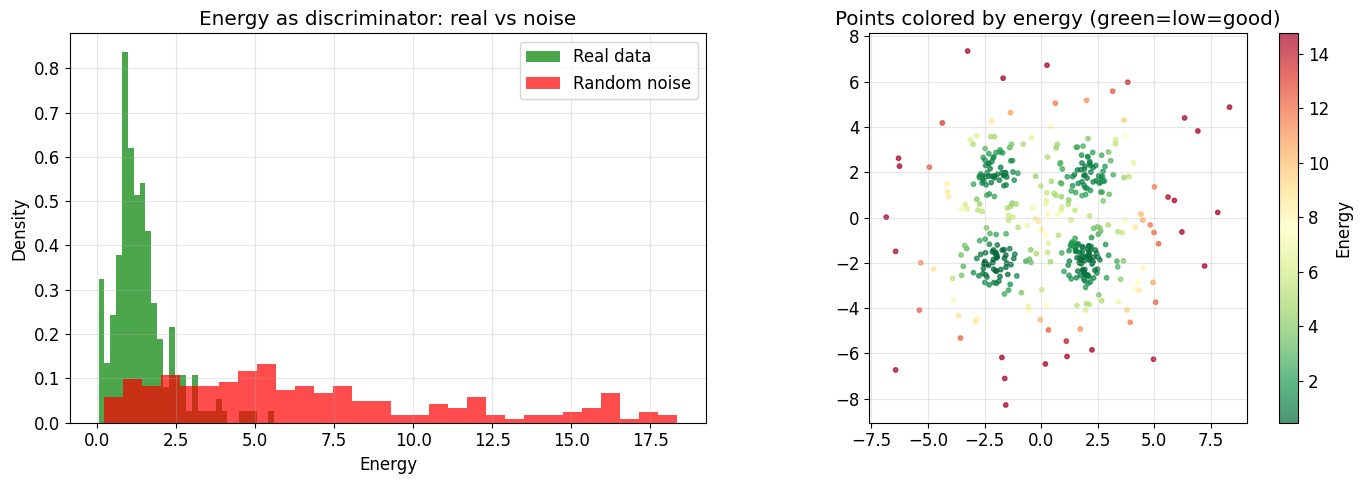

Mean energy — Real: 1.42, Noise: 6.73
The energy function correctly assigns lower energy to real data!


In [37]:
# Use the energy to discriminate: score real data vs noise
energy_model.eval()

# Real data
real_pts = data_dsm[:200]
# Random noise
noise_pts = torch.randn(200, 2).to(device) * 3

t_score = torch.full((200,), 10.0, device=device)  # low noise level

with torch.no_grad():
    E_real = energy_model.compute_energy(real_pts, t_score).cpu().numpy()
    E_noise = energy_model.compute_energy(noise_pts, t_score).cpu().numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(E_real, bins=30, alpha=0.7, label='Real data', color='green', density=True)
ax1.hist(E_noise, bins=30, alpha=0.7, label='Random noise', color='red', density=True)
ax1.set_xlabel('Energy'); ax1.set_ylabel('Density')
ax1.set_title('Energy as discriminator: real vs noise')
ax1.legend(); ax1.grid(True, alpha=0.3)

# Scatter with energy coloring
all_pts = torch.cat([real_pts, noise_pts]).cpu().numpy()
all_E = np.concatenate([E_real, E_noise])
sc = ax2.scatter(all_pts[:, 0], all_pts[:, 1], c=all_E, cmap='RdYlGn_r',
                  s=10, alpha=0.7, vmin=np.percentile(all_E, 5), vmax=np.percentile(all_E, 95))
plt.colorbar(sc, ax=ax2, label='Energy')
ax2.set_title('Points colored by energy (green=low=good)')
ax2.set_aspect('equal'); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean energy — Real: {E_real.mean():.2f}, Noise: {E_noise.mean():.2f}")
print(f"The energy function correctly assigns lower energy to real data!")

---
# Summary: What connects to which notebook

| Concept | Section | Notebook |
|---|---|---|
| Autoencoders, bottleneck compression | Part 1 | 5 (Latent Diffusion) |
| VAE: reparameterization trick | Part 2.2 | 5 |
| VAE: KL divergence regularizer | Part 2.3 | 5 |
| VAE: ELBO, and MSE as a Gaussian likelihood ($\beta = 2\sigma^2_{\text{dec}}$) | Part 2.3 | 5 |
| Beta-VAE tradeoff | Part 2.6 | 5 |
| Latent space interpolation | Part 2.5 | 5 |
| Energy functions as quality scores | Part 3.1-3.2 | 6 (Gradient Optimization), 7 (EBM) |
| Boltzmann distribution $p \propto e^{-E}$; normalizability; energy up to a constant | Part 3.2 | 7 |
| Energy gradients for steering (sign, $dt$-scaling, noisy vs. denoised input) | Part 3.5 | 6 |
| Energy for discrimination | Part 3.4 | 7 |
| Brownian motion / Wiener process | Part 4.2 | 7 |
| Euler-Maruyama SDE solver | Part 4.3 | 7 |
| VP-SDE noise schedule = DDPM with T=1000 | Part 4.5 | 1, 7 |
| Forward/reverse SDE duality | Part 4.6 | 7 |
| DDPM sampling = discretised reverse SDE | Part 4.7 | 1-3, 7 |
| Probability-flow ODE | Part 4.8 | 3b, 4 (flow matching), DDIM |
| `create_graph=True` for second-order gradients | Part 5.2 | 6, 7 |
| Hessians and curvature | Part 5.3 | 7 |
| Score matching with energy networks | Part 5.4, 6.1 | 7 |
| `enable_grad()` during inference | Part 5.6 | 6 |
| Denoising score matching (full pipeline) = weighted $\epsilon$-loss | Part 6 | 7 |

Combined with notebooks 0a (calculus, vector fields, ODE solving) and 0b (probability, score functions, Langevin dynamics), you now have the mathematical foundation for all the diffusion notebooks. Notebook 3b, read between notebooks 3 and 4, ties DDPM, scores and flow matching together.